# Geração Musical Simbólica no Dataset Nottingham — RNN vs. Transformer

**Projeto Final DCC831 — IA Generativa para Música (UFMG)**

Este notebook implementa o pipeline completo do Projeto Final de geração musical simbólica com redes neurais autoregressivas implementadas nativamente em PyTorch:

1. **Preparação e filtragem do corpus (`Nottingham`)**: download do repositório `jukedeck/nottingham-dataset`, validação dos arquivos MIDI e filtragem exclusiva das composições completas (`MIDI/`, contendo melodia + acompanhamento de acordes), eliminando duplicatas das subpastas `melody/` e `chords/` antes da análise estatística e evitando vazamento de dados (*data leakage*).
2. **Divisão por música (80% / 10% / 10%)**: separação determinística (`SEED = 42`) em treino, validação e teste por composição. O conjunto de teste é reservado exclusivamente para a avaliação final.
3. **Tokenização (`MIDILike`) com tessitura completa**: codificação via `miditok` com `pitch_range=(36, 89)`, preservando 100% das alturas presentes no corpus (`36` a `88`, incluindo as fundamentais graves dos acordes).
4. ***Data Augmentation* e Janelamento Deslizante (*Sliding Window*)**: aumento de dados por transposição cromática (`-2` a `+2` semitons) restrito ao conjunto de treino e extração de janelas deslizantes (`WINDOW_SIZE = 1024`, `STRIDE = 512`, `BATCH_SIZE = 32`) compartilhadas entre os modelos.
5. **Modelos Autoregressivos em PyTorch**:
   - ***Baseline* (`MusicRNN`)**: RNN *vanilla* autoregressiva (Elman `nn.RNN` com ativação `tanh`, sem portas de memória) de 1 camada (`embedding_dim=64`, `hidden_dim=128`).
   - **Modelo Principal (`MusicTransformer`)**: Transformer *decoder-only* causal Pre-LN de 6 camadas (`d_model=256`, `nhead=8`, `dim_feedforward=1024`, ativação `GELU`, *weight tying* e inicialização estilo GPT-2), treinado com `AdamW` (grupos com/sem *weight decay*), `OneCycleLR` e *Early Stopping*.
6. **Geração e Estudo de Amostragem**: decodificação estocástica com temperatura, *top-k* e *top-p* (*nucleus sampling*), mais estudo do efeito da temperatura (`T = 0.8, 0.9, 1.0`).
7. **Avaliação Objetiva e Entregáveis**: cálculo de perplexidade no teste, geração de 100 amostras por modelo, avaliação de 5 métricas musicais objetivas comparando distribuições contra o conjunto de teste humano (*Overlap Area* e Divergência KL, conforme Yang & Lerch, 2020), geração das curvas de treino/validação e síntese de áudio (`.wav`) local (via FluidSynth quando disponível ou síntese nativa em Python).

---
> **Versão Local (`_Local` — Windows / GPU NVIDIA CUDA):** adaptada para execução local sem dependências do Google Colab (`google.colab`) ou comandos Linux (`apt-get`). Todos os arquivos, checkpoints e resultados são salvos localmente em `./nottingham_project`.

## 1. Instalar dependências e verificar GPU (Execução Local)

> **Importante (Windows + GPU NVIDIA RTX 5070):** utilize um kernel/ambiente virtual com **Python 3.12 ou 3.13** para contar com *wheels* pré-compilados do PyTorch com CUDA (`cu128+`, necessário para a arquitetura Blackwell `sm_120`). A célula abaixo instala os pacotes do projeto e verifica (ou instala automaticamente) o PyTorch com suporte a CUDA.

In [1]:
import importlib
import importlib.util
import subprocess
import sys

PACKAGE_IMPORTS = {
    "pretty_midi": "pretty_midi",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "tqdm": "tqdm",
    "scikit-learn": "sklearn",
    "miditok": "miditok",
    "scipy": "scipy",
    "jinja2": "jinja2",
    "ipywidgets": "ipywidgets",
}

missing = [pkg for pkg, mod in PACKAGE_IMPORTS.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Instalando pacotes ausentes:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

try:
    import torch
    has_cuda_build = torch.version.cuda is not None
except ImportError:
    torch = None
    has_cuda_build = False

if not has_cuda_build:
    if sys.version_info >= (3, 14):
        raise RuntimeError(
            f"Python {sys.version.split()[0]} detectado sem PyTorch CUDA. "
            "Selecione o kernel 'Python 3.12 (GenAIMusic RTX 5070)' (.venv) no topo direito do notebook."
        )
    print("Instalando PyTorch com suporte a CUDA (cu128 — compatível com RTX 5070 / Blackwell)...")
    res = subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "--upgrade",
            "torch", "--index-url", "https://download.pytorch.org/whl/cu128",
        ],
        capture_output=True,
        text=True,
    )
    if res.returncode != 0:
        print(res.stderr[-2500:])
        raise RuntimeError("Falha ao instalar PyTorch com CUDA (cu128).")
    if "torch" in sys.modules:
        raise RuntimeError("PyTorch instalado! Reinicie o Kernel e execute novamente.")
    torch = importlib.import_module("torch")

if torch.cuda.is_available():
    torch.set_float32_matmul_precision("high")
    props = torch.cuda.get_device_properties(0)
    _ = (torch.zeros(1, device="cuda") + 1).item()
    print(f"Python  : {sys.version.split()[0]} ({sys.executable})")
    print(f"PyTorch : {torch.__version__} (CUDA {torch.version.cuda})")
    print(f"GPU OK  : {props.name} | {props.total_memory / (1024**3):.1f} GB VRAM | Compute {props.major}.{props.minor}")
else:
    print(f"Python  : {sys.version.split()[0]} ({sys.executable})")
    print(f"PyTorch : {torch.__version__} (CUDA {torch.version.cuda})")
    print("ATENÇÃO : `torch.cuda.is_available()` retornou False — selecione o kernel 'Python 3.12 (GenAIMusic RTX 5070)'.")

Python  : 3.12.16 (c:\Users\lucas\Dev\UFMG\GenAIMusic\.venv\Scripts\python.exe)
PyTorch : 2.11.0+cu128 (CUDA 12.8)
GPU OK  : NVIDIA GeForce RTX 5070 | 11.9 GB VRAM | Compute 12.0


## 2. Baixar o dataset

O notebook clona o repositório público `jukedeck/nottingham-dataset` do GitHub. Se o repositório mudar de estrutura, a etapa seguinte procura recursivamente por arquivos `.mid` e `.midi`.

In [2]:
from pathlib import Path
import subprocess
import shutil
import os

PROJECT_ROOT = (
    Path.cwd() / "UFMG" / "GenAIMusic"
    if (Path.cwd() / "UFMG" / "GenAIMusic").exists()
    else Path.cwd()
)
BASE_DIR = (PROJECT_ROOT / "nottingham_project").resolve()
RAW_DIR = BASE_DIR / "raw"
REPO_DIR = RAW_DIR / "nottingham-dataset"

BASE_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)

if not REPO_DIR.exists():
    result = subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/jukedeck/nottingham-dataset.git",
         str(REPO_DIR)],
        capture_output=True, text=True
    )
    if result.returncode != 0:
        print(result.stderr[-3000:])
        raise RuntimeError(
            "Não foi possível clonar o repositório. Confira se o `git` está instalado e tente novamente."
        )
else:
    print("Repositório já existe; mantendo os arquivos baixados.")

midi_paths = sorted(
    (
        p for p in REPO_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in {".mid", ".midi"}
    ),
    key=lambda p: p.relative_to(REPO_DIR).as_posix(),
)

print(f"Diretório base local: {BASE_DIR}")
print(f"Repositório: {REPO_DIR}")
print(f"Arquivos MIDI encontrados: {len(midi_paths):,}")
if not midi_paths:
    raise RuntimeError("Nenhum MIDI encontrado. Inspecione a estrutura do repositório.")
print("Exemplos:")
for p in midi_paths[:10]:
    print(" -", p.relative_to(REPO_DIR).as_posix())

Repositório já existe; mantendo os arquivos baixados.
Diretório base local: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project
Repositório: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\raw\nottingham-dataset
Arquivos MIDI encontrados: 3,089
Exemplos:
 - MIDI/ashover1.mid
 - MIDI/ashover10.mid
 - MIDI/ashover11.mid
 - MIDI/ashover12.mid
 - MIDI/ashover13.mid
 - MIDI/ashover14.mid
 - MIDI/ashover15.mid
 - MIDI/ashover16.mid
 - MIDI/ashover17.mid
 - MIDI/ashover18.mid


## 3. Inspecionar e validar os arquivos MIDI

A inspeção coleta duração, número de instrumentos, notas, faixa de alturas e andamento. Arquivos que não puderem ser lidos serão registrados como inválidos, sem interromper o processamento do restante do corpus.

In [3]:
import pretty_midi
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

records = []
errors = []

for path in tqdm(midi_paths, desc="Lendo MIDI"):
    try:
        midi = pretty_midi.PrettyMIDI(str(path))
        notes = [
            note
            for instrument in midi.instruments
            for note in instrument.notes
        ]
        duration = float(midi.get_end_time())
        pitches = [n.pitch for n in notes]
        tempos = midi.get_tempo_changes()[1]
        finite_tempos = [float(t) for t in tempos if np.isfinite(t) and t > 0]

        records.append({
            "relative_path": path.relative_to(REPO_DIR).as_posix(),
            "absolute_path": str(path),
            "filename": path.name,
            "duration_seconds": duration,
            "n_instruments": len(midi.instruments),
            "n_notes": len(notes),
            "pitch_min": min(pitches) if pitches else np.nan,
            "pitch_max": max(pitches) if pitches else np.nan,
            "pitch_range": (max(pitches) - min(pitches)) if pitches else np.nan,
            "tempo_median": float(np.median(finite_tempos)) if finite_tempos else np.nan,
            "has_drums": any(inst.is_drum for inst in midi.instruments),
            "valid": len(notes) > 0 and duration > 0,
        })
    except Exception as exc:
        errors.append({
            "relative_path": path.relative_to(REPO_DIR).as_posix(),
            "error": repr(exc),
        })

df_all = pd.DataFrame(records)
errors_df = pd.DataFrame(errors)

print(f"Arquivos lidos: {len(df_all):,}")
print(f"Arquivos com erro de leitura: {len(errors_df):,}")
print(f"Arquivos válidos (com notas e duração positiva): {int(df_all['valid'].sum()) if not df_all.empty else 0:,}")

display(df_all.head())
if not errors_df.empty:
    display(errors_df.head(10))

Lendo MIDI:   0%|          | 0/3089 [00:00<?, ?it/s]

c:\Users\lucas\Dev\UFMG\GenAIMusic\.venv\Lib\site-packages\pretty_midi\pretty_midi.py:122: RuntimeWarning: Tempo, Key or Time signature change events found on non-zero tracks.  This is not a valid type 0 or type 1 MIDI file.  Tempo, Key or Time Signature may be wrong.
  warnings.warn(


Arquivos lidos: 3,089
Arquivos com erro de leitura: 0
Arquivos válidos (com notas e duração positiva): 3,089


,relative_path,absolute_path,filename,duration_seconds,n_instruments,n_notes,pitch_min,pitch_max,pitch_range,tempo_median,has_drums,valid
0,MIDI/ashover1.mid,C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_...,ashover1.mid,47.5,2,158,36,79,43,120.0,False,True
1,MIDI/ashover10.mid,C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_...,ashover10.mid,130.0,2,639,36,84,48,120.0,False,True
2,MIDI/ashover11.mid,C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_...,ashover11.mid,49.5,2,349,36,81,45,120.0,False,True
3,MIDI/ashover12.mid,C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_...,ashover12.mid,66.0,2,365,36,84,48,120.0,False,True
4,MIDI/ashover13.mid,C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_...,ashover13.mid,64.0,2,510,36,81,45,120.0,False,True


## 4. Filtragem das composições completas e resumo estatístico do corpus

O repositório `jukedeck/nottingham-dataset` armazena três versões de cada peça: a música completa na raiz `MIDI/` (melodia + acordes) e faixas separadas em `MIDI/melody/` e `MIDI/chords/`. Filtramos **apenas as composições completas (`source_folder == "complete"`)** já nesta etapa para que todas as estatísticas descritivas, histogramas e inspeções reflitam exatamente o corpus utilizado nos experimentos, sem contagem tripla.

In [4]:
from pathlib import Path

valid_df = df_all[df_all["valid"]].copy()

if valid_df.empty:
    raise RuntimeError("Não há arquivos válidos para preparar.")

valid_df["source_folder"] = valid_df["relative_path"].apply(
    lambda p: Path(p).parts[1] if len(Path(p).parts) > 2 else "complete"
)
valid_df["composition_id"] = valid_df["relative_path"].apply(
    lambda p: Path(p).stem
)

print("Arquivos válidos no repositório por categoria:")
print(valid_df["source_folder"].value_counts().to_string())

# Mantém exclusivamente as músicas completas (melodia + acordes)
valid_df = (
    valid_df[valid_df["source_folder"] == "complete"]
    .copy()
    .reset_index(drop=True)
)
print(f"\nCorpus filtrado (composições completas): {len(valid_df):,} músicas")

summary = valid_df[
    ["duration_seconds", "n_instruments", "n_notes",
     "pitch_min", "pitch_max", "pitch_range", "tempo_median"]
].describe(percentiles=[.25, .5, .75]).T

display(summary.round(2))
print("\nArquivos com bateria:", int(valid_df["has_drums"].sum()))
print("Instrumentos por arquivo (corpus completo filtrado):")
display(
    valid_df["n_instruments"]
    .value_counts()
    .sort_index()
    .rename_axis("n_instruments")
    .to_frame("n_files")
)

Arquivos válidos no repositório por categoria:
source_folder
complete    1034
melody      1034
chords      1021

Corpus filtrado (composições completas): 1,034 músicas


,count,mean,std,min,25%,50%,75%,max
duration_seconds,1034.0,67.64,44.91,12.0,49.50,64.0,66.00,769.5
n_instruments,1034.0,1.99,0.11,1.0,2.00,2.0,2.00,2.0
n_notes,1034.0,344.55,235.93,24.0,238.25,301.0,368.75,3868.0
pitch_min,1034.0,37.41,3.04,36.0,36.00,38.0,38.00,69.0
pitch_max,1034.0,80.39,2.69,69.0,79.00,81.0,83.00,88.0
pitch_range,1034.0,42.98,3.93,12.0,43.00,43.0,45.00,52.0
tempo_median,1034.0,120.00,0.00,120.0,120.00,120.0,120.00,120.0



Arquivos com bateria: 0
Instrumentos por arquivo (corpus completo filtrado):


,n_files
n_instruments,
1,13
2,1021


## 5. Visualizar distribuições

Use os gráficos para procurar arquivos extremamente curtos/longos, quantidade de notas atípica e faixa de alturas incomum. Não remova automaticamente outliers sem verificar se há uma justificativa musical.

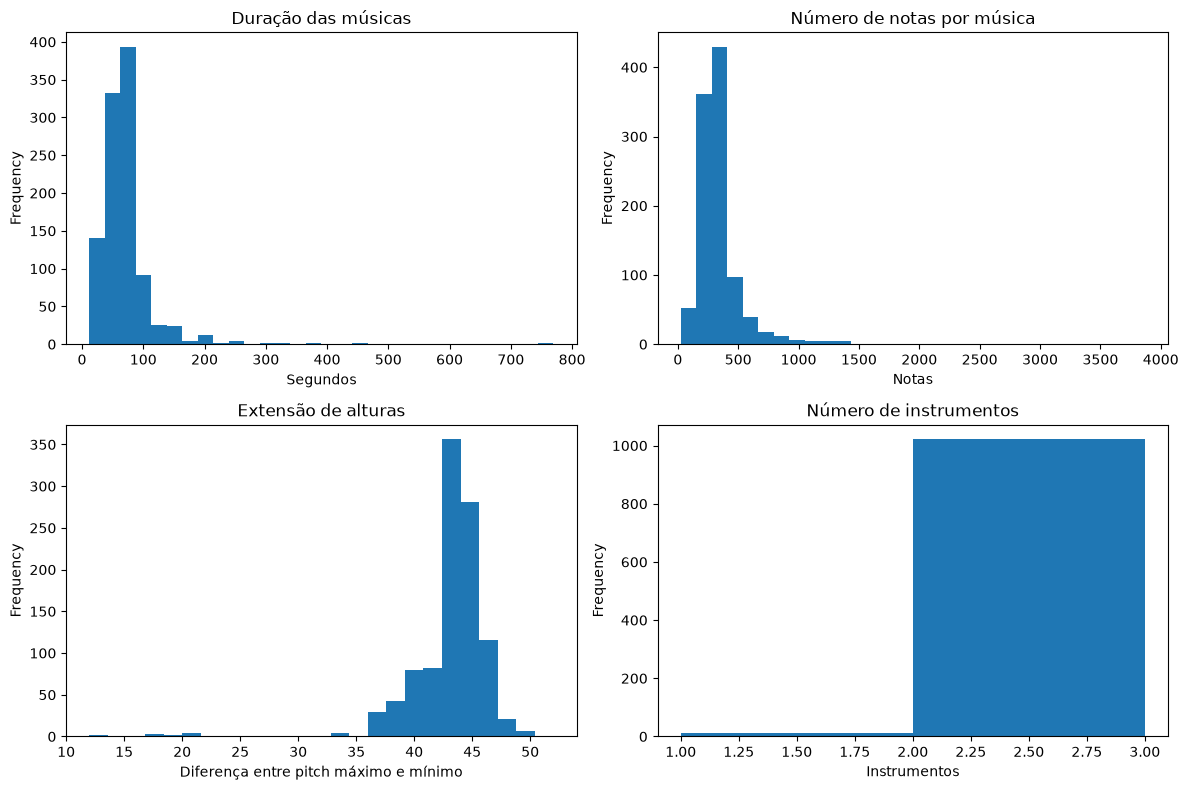

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

valid_df["duration_seconds"].plot(kind="hist", bins=30, ax=axes[0, 0])
axes[0, 0].set_title("Duração das músicas")
axes[0, 0].set_xlabel("Segundos")

valid_df["n_notes"].plot(kind="hist", bins=30, ax=axes[0, 1])
axes[0, 1].set_title("Número de notas por música")
axes[0, 1].set_xlabel("Notas")

valid_df["pitch_range"].dropna().plot(kind="hist", bins=25, ax=axes[1, 0])
axes[1, 0].set_title("Extensão de alturas")
axes[1, 0].set_xlabel("Diferença entre pitch máximo e mínimo")

valid_df["n_instruments"].plot(kind="hist", bins=range(1, int(valid_df["n_instruments"].max()) + 2), ax=axes[1, 1])
axes[1, 1].set_title("Número de instrumentos")
axes[1, 1].set_xlabel("Instrumentos")

plt.tight_layout()
plt.show()

## 6. Identificar casos que merecem inspeção

Esta célula apenas lista candidatos a inspeção manual. Não os exclui automaticamente. Os limites são heurísticos e podem ser ajustados depois de observar as distribuições.

In [6]:
candidates = valid_df[
    (valid_df["duration_seconds"] < 5) |
    (valid_df["duration_seconds"] > valid_df["duration_seconds"].quantile(.99)) |
    (valid_df["n_notes"] < 10) |
    (valid_df["n_notes"] > valid_df["n_notes"].quantile(.99)) |
    (valid_df["pitch_range"] > 60)
].copy()

print(f"Candidatos à inspeção: {len(candidates):,}")
display(
    candidates.sort_values("duration_seconds")[
        ["relative_path", "duration_seconds", "n_notes", "n_instruments",
         "pitch_min", "pitch_max", "pitch_range"]
    ].head(30)
)

Candidatos à inspeção: 13


,relative_path,duration_seconds,n_notes,n_instruments,pitch_min,pitch_max,pitch_range
429,MIDI/jigs8.mid,193.5,1300,2,38,81,43
452,MIDI/morris10.mid,193.5,1418,2,36,79,43
453,MIDI/morris11.mid,234.0,1080,2,36,81,45
803,MIDI/reelsm-q56.mid,241.5,1400,2,36,81,45
481,MIDI/morris9.mid,243.0,1243,2,38,81,43
944,MIDI/reelsu-z28.mid,256.0,1356,2,37,81,44
431,MIDI/jigs81.mid,264.0,1658,2,38,81,43
464,MIDI/morris21.mid,306.0,1415,2,36,84,48
456,MIDI/morris14.mid,338.0,1807,2,38,79,41
458,MIDI/morris16.mid,370.0,1836,2,36,77,41


## 7. Criar treino, validação e teste por música

A divisão é feita sobre os arquivos MIDI apenas, sem contar chords e melody, antes de recortar ou tokenizar sequências. Isso evita que trechos da mesma música apareçam em mais de uma partição. A proporção inicial é 80/10/10 e a semente fixa permite reproduzir a divisão.

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
from pathlib import Path
from sklearn.model_selection import train_test_split

SEED = 42
VAL_FRAC = 0.10
TEST_FRAC = 0.10

# Garante idempotência caso esta célula seja reexecutada isoladamente
if "source_folder" not in valid_df.columns:
    valid_df["source_folder"] = valid_df["relative_path"].apply(
        lambda p: Path(p).parts[1] if len(Path(p).parts) > 2 else "complete"
    )
    valid_df["composition_id"] = valid_df["relative_path"].apply(
        lambda p: Path(p).stem
    )

valid_df = (
    valid_df[valid_df["valid"] & (valid_df["source_folder"] == "complete")]
    .copy()
    .reset_index(drop=True)
)

composition_ids = valid_df["composition_id"].to_numpy()

train_ids, temp_ids = train_test_split(
    composition_ids,
    test_size=VAL_FRAC + TEST_FRAC,
    random_state=SEED,
    shuffle=True,
)

val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
    random_state=SEED,
    shuffle=True,
)

split_map = {
    **{cid: "train" for cid in train_ids},
    **{cid: "validation" for cid in val_ids},
    **{cid: "test" for cid in test_ids},
}

valid_df["split"] = valid_df["composition_id"].map(split_map)

splits = {
    name: valid_df[valid_df["split"] == name].reset_index(drop=True)
    for name in ["train", "validation", "test"]
}

print(f"Composições completas: {len(valid_df):,}")
for name, split_df in splits.items():
    print(
        f"{name:10s}: "
        f"{split_df['composition_id'].nunique():4,d} composições | "
        f"{len(split_df):5,d} arquivos"
    )

Composições completas: 1,034
train     :  827 composições |   827 arquivos
validation:  103 composições |   103 arquivos
test      :  104 composições |   104 arquivos


## 8. Salvar uma estrutura de dataset pronta para os próximos notebooks

Os arquivos válidos serão copiados para pastas separadas, mantendo os nomes originais com um prefixo numérico para evitar colisões. Também serão salvos os metadados e os manifestos CSV. O diretório `test` deve ser reservado para a avaliação final.

In [9]:
from pathlib import Path
import shutil

PREPARED_DIR = BASE_DIR / "prepared"
if PREPARED_DIR.exists():
    shutil.rmtree(PREPARED_DIR)

for split_name, split_df in splits.items():
    split_dir = PREPARED_DIR / split_name
    split_dir.mkdir(parents=True, exist_ok=True)

    rows = []
    for idx, row in enumerate(split_df.to_dict("records")):
        source = Path(row["absolute_path"])
        target_name = f"{idx:05d}_{source.stem}{source.suffix.lower()}"
        target = split_dir / target_name
        shutil.copy2(source, target)

        rows.append({
            **row,
            "prepared_path": str(target),
            "split": split_name,
        })

    pd.DataFrame(rows).to_csv(PREPARED_DIR / f"{split_name}.csv", index=False)

df_all.to_csv(PREPARED_DIR / "all_readable_files.csv", index=False)
errors_df.to_csv(PREPARED_DIR / "read_errors.csv", index=False)

print("Dataset preparado em:", PREPARED_DIR)
for split_name in splits:
    print(f"{split_name:10s}: {len(list((PREPARED_DIR / split_name).glob('*'))):,} arquivos")

Dataset preparado em: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\prepared
train     : 827 arquivos
validation: 103 arquivos
test      : 104 arquivos


## 9. Verificar a separação e salvar um relatório resumido

A verificação confirma que os caminhos de origem não se repetem entre as partições. Como a unidade de divisão é a música, essa é a checagem principal contra vazamento entre conjuntos.

In [10]:

source_sets = {
    name: set(split_df["relative_path"])
    for name, split_df in splits.items()
}

overlap = (
    source_sets["train"] & source_sets["validation"]
    | source_sets["train"] & source_sets["test"]
    | source_sets["validation"] & source_sets["test"]
)

TRAIN_FRAC = 0.80

report = {
    "dataset": "Nottingham",
    "source_repository": "https://github.com/jukedeck/nottingham-dataset",
    "seed": SEED,
    "split_ratios": {
        "train": TRAIN_FRAC,
        "validation": VAL_FRAC,
        "test": TEST_FRAC
    },
    "n_midi_found": len(midi_paths),
    "n_readable": len(df_all),
    "n_invalid_or_empty": int((~df_all["valid"]).sum()),
    "n_read_errors": len(errors_df),
    "n_valid": len(valid_df),
    "split_sizes": {
        name: len(split_df)
        for name, split_df in splits.items()
    },
    "duration_median_seconds": float(valid_df["duration_seconds"].median()),
    "notes_median": float(valid_df["n_notes"].median()),
    "instruments_median": float(valid_df["n_instruments"].median()),
}

import json

with open(PREPARED_DIR / "dataset_report.json", "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

print(json.dumps(report, ensure_ascii=False, indent=2))

if overlap:
    print("\nAtenção: existem arquivos em mais de uma partição.")
else:
    print("\nVerificação concluída: nenhuma música aparece em mais de uma partição.")


{
  "dataset": "Nottingham",
  "source_repository": "https://github.com/jukedeck/nottingham-dataset",
  "seed": 42,
  "split_ratios": {
    "train": 0.8,
    "validation": 0.1,
    "test": 0.1
  },
  "n_midi_found": 3089,
  "n_readable": 3089,
  "n_invalid_or_empty": 0,
  "n_read_errors": 0,
  "n_valid": 1034,
  "split_sizes": {
    "train": 827,
    "validation": 103,
    "test": 104
  },
  "duration_median_seconds": 64.0,
  "notes_median": 301.0,
  "instruments_median": 2.0
}

Verificação concluída: nenhuma música aparece em mais de uma partição.


## 10. Baixar o dataset preparado

Esta célula compacta as pastas `prepared/` para facilitar o download e o compartilhamento com os demais integrantes. O arquivo compactado inclui MIDI, CSVs e relatório.

In [11]:
import shutil

archive_path = shutil.make_archive(
    str(BASE_DIR / "nottingham_prepared"),
    "zip",
    root_dir=PREPARED_DIR
)
print("Arquivo ZIP criado localmente:", archive_path)

Arquivo ZIP criado localmente: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\nottingham_prepared.zip


# Tokenização

In [12]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("miditok") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "miditok"])
print("miditok pronto.")

miditok pronto.


In [13]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import miditok

from miditok import MIDILike, TokenizerConfig

if "BASE_DIR" not in globals():
    _project_root = (
        Path.cwd() / "UFMG" / "GenAIMusic"
        if (Path.cwd() / "UFMG" / "GenAIMusic").exists()
        else Path.cwd()
    )
    BASE_DIR = (_project_root / "nottingham_project").resolve()
DATA_DIR = BASE_DIR / "prepared"
TOKEN_DIR = BASE_DIR / "tokenized"
TOKEN_DIR.mkdir(parents=True, exist_ok=True)

for split in ["train", "validation", "test"]:
    assert (DATA_DIR / f"{split}.csv").exists(), (
        f"Manifesto não encontrado: {DATA_DIR / f'{split}.csv'}. "
        "Execute primeiro as células de preparação do dataset acima."
    )

# O corpus Nottingham contém notas MIDI de 36 (C2, graves dos acordes) até 88 (E6).
# Usamos pitch_range=(36, 89) para preservar 100% das notas graves e agudas do corpus.
config = TokenizerConfig(
    pitch_range=(36, 89),
    beat_res={(0, 4): 4, (4, 12): 4},
    num_velocities=16,
    use_programs=True,
    one_token_stream_for_programs=True,
    use_tempos=False,
    use_time_signatures=False,
    use_chords=False,
    use_rests=False,
    special_tokens=["PAD", "BOS", "EOS", "MASK"],
)

tokenizer = MIDILike(config)

assert "NoteOn_36" in tokenizer.vocab and "NoteOn_88" in tokenizer.vocab, (
    "A faixa de alturas 36–88 não foi totalmente coberta pelo vocabulário!"
)

print("Tamanho do vocabulário:", len(tokenizer))
print("Cobertura de alturas verificada: NoteOn_36 até NoteOn_88 presentes.")
print("Diretório de saída:", TOKEN_DIR)

Tamanho do vocabulário: 429
Cobertura de alturas verificada: NoteOn_36 até NoteOn_88 presentes.
Diretório de saída: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\tokenized


In [14]:
import pretty_midi

all_notes = []

for split in ["train", "validation", "test"]:
    manifest = pd.read_csv(DATA_DIR / f"{split}.csv")

    for midi_path in manifest["prepared_path"]:
        midi = pretty_midi.PrettyMIDI(midi_path)
        all_notes.extend(
            note.pitch
            for instrument in midi.instruments
            for note in instrument.notes
        )

print("Menor altura MIDI:", min(all_notes))
print("Maior altura MIDI:", max(all_notes))
print("Notas fora de 0–127:", sum(p < 0 or p > 127 for p in all_notes))

c:\Users\lucas\Dev\UFMG\GenAIMusic\.venv\Lib\site-packages\pretty_midi\pretty_midi.py:122: RuntimeWarning: Tempo, Key or Time signature change events found on non-zero tracks.  This is not a valid type 0 or type 1 MIDI file.  Tempo, Key or Time Signature may be wrong.
  warnings.warn(


Menor altura MIDI: 36
Maior altura MIDI: 88
Notas fora de 0–127: 0


In [15]:
from tqdm.auto import tqdm

def get_token_ids(path):
    encoded = tokenizer(str(path))

    if isinstance(encoded, list):
        if len(encoded) != 1:
            raise ValueError(
                f"Esperava uma sequência por música, mas encontrei {len(encoded)}."
            )
        encoded = encoded[0]

    return encoded.ids, encoded

token_stats = []

for split in ["train", "validation", "test"]:
    manifest = pd.read_csv(DATA_DIR / f"{split}.csv")
    output_path = TOKEN_DIR / f"{split}.jsonl"

    with output_path.open("w", encoding="utf-8") as f:
        for row in tqdm(
            manifest.to_dict("records"),
            desc=f"Tokenizando {split}"
        ):
            midi_path = Path(row["prepared_path"])
            ids, _ = get_token_ids(midi_path)

            if not ids:
                continue

            record = {
                "split": split,
                "relative_path": row["relative_path"],
                "midi_filename": midi_path.name,
                "ids": ids,
                "length": len(ids),
            }

            f.write(json.dumps(record, ensure_ascii=False) + "\n")

            token_stats.append({
                "split": split,
                "relative_path": row["relative_path"],
                "length": len(ids),
            })

    print(f"Salvo: {output_path}")

Tokenizando train:   0%|          | 0/827 [00:00<?, ?it/s]

Salvo: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\tokenized\train.jsonl


Tokenizando validation:   0%|          | 0/103 [00:00<?, ?it/s]

Salvo: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\tokenized\validation.jsonl


Tokenizando test:   0%|          | 0/104 [00:00<?, ?it/s]

Salvo: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\tokenized\test.jsonl


,count,mean,median,std,min,max
split,,,,,,
test,104,2003.05,1709.0,1299.50,696,7572
train,827,1900.39,1673.0,1322.04,138,22066
validation,103,1943.15,1650.0,1273.59,523,10014


Tamanho do vocabulário: 429


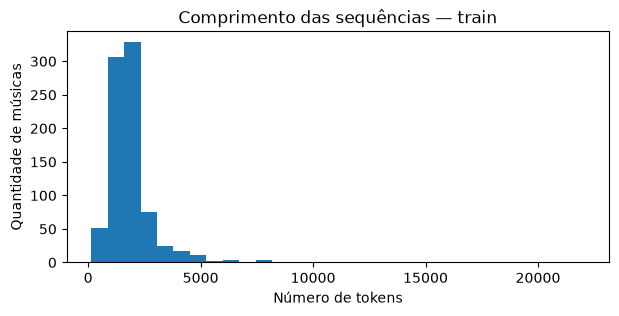

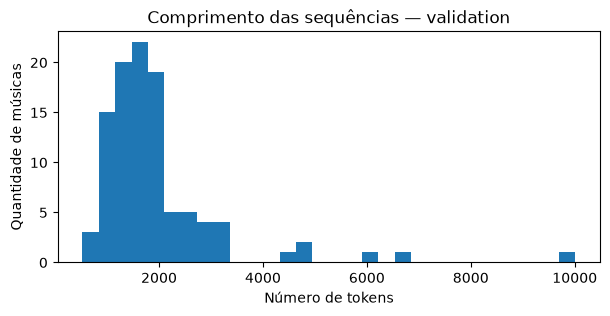

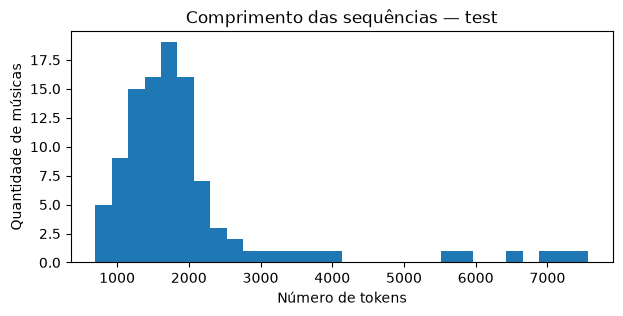

In [16]:
stats_df = pd.DataFrame(token_stats)

summary = (
    stats_df.groupby("split")["length"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(summary)

print("Tamanho do vocabulário:", len(tokenizer))

import matplotlib.pyplot as plt

for split in ["train", "validation", "test"]:
    lengths = stats_df.loc[stats_df["split"] == split, "length"]

    plt.figure(figsize=(7, 3))
    plt.hist(lengths, bins=30)
    plt.title(f"Comprimento das sequências — {split}")
    plt.xlabel("Número de tokens")
    plt.ylabel("Quantidade de músicas")
    plt.show()

In [17]:
train_file = TOKEN_DIR / "train.jsonl"

with train_file.open(encoding="utf-8") as f:
    example = json.loads(next(f))

ids = example["ids"]
vocab = tokenizer.vocab

print("Arquivo:", example["midi_filename"])
print("Quantidade de tokens:", len(ids))
print("Primeiros 50 IDs:", ids[:50])

Arquivo: 00000_ashover1.mid
Quantidade de tokens: 860
Primeiros 50 IDs: [135, 300, 44, 122, 131, 300, 98, 300, 42, 122, 300, 11, 122, 300, 15, 122, 300, 18, 122, 135, 300, 96, 300, 39, 122, 131, 300, 65, 300, 69, 300, 72, 300, 93, 300, 37, 122, 300, 6, 122, 300, 10, 122, 300, 13, 122, 133, 300, 91, 300]


In [18]:
vocab_inv = {idx: token for token, idx in tokenizer.vocab.items()}

print("Arquivo:", example["midi_filename"])
print("Quantidade de tokens:", len(ids))
print("\nPrimeiros 50 tokens:")
print([vocab_inv.get(i, f"ID_DESCONHECIDO_{i}") for i in ids[:50]])

Arquivo: 00000_ashover1.mid
Quantidade de tokens: 860

Primeiros 50 tokens:
['TimeShift_2.0.4', 'Program_0', 'NoteOn_76', 'Velocity_87', 'TimeShift_1.0.4', 'Program_0', 'NoteOff_76', 'Program_0', 'NoteOn_74', 'Velocity_87', 'Program_0', 'NoteOn_43', 'Velocity_87', 'Program_0', 'NoteOn_47', 'Velocity_87', 'Program_0', 'NoteOn_50', 'Velocity_87', 'TimeShift_2.0.4', 'Program_0', 'NoteOff_74', 'Program_0', 'NoteOn_71', 'Velocity_87', 'TimeShift_1.0.4', 'Program_0', 'NoteOff_43', 'Program_0', 'NoteOff_47', 'Program_0', 'NoteOff_50', 'Program_0', 'NoteOff_71', 'Program_0', 'NoteOn_69', 'Velocity_87', 'Program_0', 'NoteOn_38', 'Velocity_87', 'Program_0', 'NoteOn_42', 'Velocity_87', 'Program_0', 'NoteOn_45', 'Velocity_87', 'TimeShift_1.2.4', 'Program_0', 'NoteOff_69', 'Program_0']


In [19]:
example_path = DATA_DIR / "train.csv"
manifest = pd.read_csv(example_path)

original_path = Path(manifest.iloc[0]["prepared_path"])
ids, encoded = get_token_ids(original_path)

reconstructed = tokenizer.decode(encoded)

output_midi = TOKEN_DIR / "reconstruction_test.mid"
reconstructed.dump_midi(str(output_midi))

print("Original:", original_path)
print("Reconstruído:", output_midi)
print("Arquivo reconstruído existe:", output_midi.exists())
print("Tamanho:", output_midi.stat().st_size, "bytes")

Original: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\prepared\train\00000_ashover1.mid
Reconstruído: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\tokenized\reconstruction_test.mid
Arquivo reconstruído existe: True
Tamanho: 1152 bytes


In [20]:
tokenizer.save(str(TOKEN_DIR / "tokenizer.json"))

stats_df.to_csv(TOKEN_DIR / "sequence_statistics.csv", index=False)

report = {
    "tokenization": "MIDI-Like",
    "dataset": "Nottingham",
    "vocabulary_size": len(tokenizer),
    "n_sequences": len(stats_df),
    "sequence_length_mean": float(stats_df["length"].mean()),
    "sequence_length_median": float(stats_df["length"].median()),
    "sequence_length_max": int(stats_df["length"].max()),
    "split_sizes": stats_df["split"].value_counts().to_dict(),
}

with (TOKEN_DIR / "tokenization_report.json").open("w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

print(json.dumps(report, ensure_ascii=False, indent=2))

{
  "tokenization": "MIDI-Like",
  "dataset": "Nottingham",
  "vocabulary_size": 429,
  "n_sequences": 1034,
  "sequence_length_mean": 1914.9748549323017,
  "sequence_length_median": 1672.5,
  "sequence_length_max": 22066,
  "split_sizes": {
    "train": 827,
    "test": 104,
    "validation": 103
  }
}


# Reconstrução do MIDI

In [21]:
import shutil

fluidsynth_bin = shutil.which("fluidsynth")
if fluidsynth_bin:
    print(f"FluidSynth detectado no PATH: {fluidsynth_bin}")
else:
    print(
        "Execução local (Windows): `fluidsynth` não está instalado no PATH (opcional).\n"
        "A reconstrução MIDI abaixo não depende dele, e a geração final de áudio (.wav) "
        "usará síntese nativa em Python automaticamente caso o FluidSynth não esteja disponível."
    )

Execução local (Windows): `fluidsynth` não está instalado no PATH (opcional).
A reconstrução MIDI abaixo não depende dele, e a geração final de áudio (.wav) usará síntese nativa em Python automaticamente caso o FluidSynth não esteja disponível.


In [22]:
from pathlib import Path
import json

if "BASE_DIR" not in globals():
    _project_root = (
        Path.cwd() / "UFMG" / "GenAIMusic"
        if (Path.cwd() / "UFMG" / "GenAIMusic").exists()
        else Path.cwd()
    )
    BASE_DIR = (_project_root / "nottingham_project").resolve()
DATA_DIR = BASE_DIR / "prepared"
TOKEN_DIR = BASE_DIR / "tokenized"
RECON_DIR = BASE_DIR / "reconstructed"
RECON_DIR.mkdir(parents=True, exist_ok=True)

with (TOKEN_DIR / "train.jsonl").open(encoding="utf-8") as f:
    example = json.loads(next(f))

filename = example.get("midi_filename", "")
source_path = Path(example.get("path", ""))

if not source_path.is_file():
    matches = [
        p for p in DATA_DIR.rglob("*")
        if p.is_file() and p.name == Path(filename).name
    ]
    if not matches:
        raise FileNotFoundError(f"MIDI original não encontrado: {filename}")
    source_path = matches[0]

encoded = tokenizer(str(source_path))
if isinstance(encoded, list):
    encoded = encoded[0]

reconstructed = tokenizer.decode(encoded)
output_path = RECON_DIR / source_path.name
reconstructed.dump_midi(str(output_path))

print("MIDI original:", source_path)
print("MIDI reconstruído:", output_path)
print("Tamanho do arquivo:", output_path.stat().st_size, "bytes")

MIDI original: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\prepared\train\00000_ashover1.mid
MIDI reconstruído: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\reconstructed\00000_ashover1.mid
Tamanho do arquivo: 1152 bytes


In [23]:
reconstructed_copy = RECON_DIR / "reconstructed.mid"
midi = pretty_midi.PrettyMIDI(str(output_path))
midi.write(str(reconstructed_copy))

print("MIDI reconstruído salvo localmente em:", reconstructed_copy)

MIDI reconstruído salvo localmente em: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\reconstructed\reconstructed.mid


# Preparação das Sequências: *Data Augmentation* e *Sliding Window*

Para enriquecer a diversidade harmônica em um corpus compacto (~827 músicas de treino) sem qualquer vazamento de dados:

1. **Transposição cromática no treino (`TRAIN_TRANSPOSITIONS = [-2, -1, 0, 1, 2]`)**: geramos versões transpostas exclusivamente das músicas de **treino** cujas notas deslocadas permanecem dentro da tessitura válida (`36–88`). Os conjuntos de **validação** e **teste** permanecem intocados em seus tons originais.
2. **Janelamento deslizante (*sliding window*)**: extraímos janelas de tamanho fixo (`WINDOW_SIZE = 1024`, `STRIDE = 512`, `BATCH_SIZE = 32`).

Exatamente o mesmo `train_loader` e `val_loader` são utilizados pelo *baseline* (`MusicRNN`) e pelo modelo principal (`MusicTransformer`), garantindo protocolo experimental idêntico.

In [24]:
import json
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

vocab = tokenizer.vocab
vocab_inv = {idx: tok for tok, idx in vocab.items()}
PAD_ID = vocab["PAD_None"]
BOS_ID = vocab["BOS_None"]
EOS_ID = vocab["EOS_None"]
VOCAB_SIZE = tokenizer.vocab_size

PITCH_MIN_VALID = 36
PITCH_MAX_VALID = 88
TRAIN_TRANSPOSITIONS = [-2, -1, 0, 1, 2]


def prepare_sequence(ids):
    ids = list(map(int, ids))

    if not ids or any(i < 0 or i >= VOCAB_SIZE for i in ids):
        return None

    if ids[0] != BOS_ID:
        ids.insert(0, BOS_ID)

    if ids[-1] != EOS_ID:
        ids.append(EOS_ID)

    return ids


def load_sequences(split):
    sequences = []
    path = TOKEN_DIR / f"{split}.jsonl"

    with path.open(encoding="utf-8") as f:
        for line in f:
            item = json.loads(line)
            ids = prepare_sequence(item["ids"])

            if ids is not None and len(ids) >= 3:
                sequences.append(ids)

    return sequences


def build_transposition_lut(semitones):
    """Cria tabela de mapeamento rápido de IDs para transposição de `semitones`."""
    lut = list(range(VOCAB_SIZE))
    for tid, tok in vocab_inv.items():
        if tok.startswith("NoteOn_") or tok.startswith("NoteOff_"):
            prefix, pitch_str = tok.split("_")
            new_pitch = int(pitch_str) + semitones
            new_tok = f"{prefix}_{new_pitch}"
            if PITCH_MIN_VALID <= new_pitch <= PITCH_MAX_VALID and new_tok in vocab:
                lut[tid] = vocab[new_tok]
            else:
                lut[tid] = -1
    return lut


def augment_with_transpositions(sequences, semitone_shifts):
    if not semitone_shifts or semitone_shifts == [0]:
        return list(sequences)

    luts = {s: build_transposition_lut(s) for s in semitone_shifts}
    augmented = []
    for seq in sequences:
        for s in semitone_shifts:
            if s == 0:
                augmented.append(seq)
                continue
            lut = luts[s]
            shifted = [lut[t] for t in seq]
            if all(t >= 0 for t in shifted):
                augmented.append(shifted)
    return augmented


train_sequences_orig = load_sequences("train")
train_sequences = augment_with_transpositions(train_sequences_orig, TRAIN_TRANSPOSITIONS)
val_sequences = load_sequences("validation")

print("Vocabulário:", VOCAB_SIZE)
print(f"Músicas de treino (originais): {len(train_sequences_orig):,}")
print(f"Músicas de treino (após transposição {TRAIN_TRANSPOSITIONS}): {len(train_sequences):,}")
print(f"Músicas de validação (sem transposição): {len(val_sequences):,}")
print("Tamanho da primeira sequência:", len(train_sequences[0]))

Vocabulário: 429
Músicas de treino (originais): 827
Músicas de treino (após transposição [-2, -1, 0, 1, 2]): 3,318
Músicas de validação (sem transposição): 103
Tamanho da primeira sequência: 862


In [25]:
WINDOW_SIZE = 1024
STRIDE = 512
BATCH_SIZE = 32


class WindowedMusicDataset(Dataset):
    """Extrai janelas deslizantes de tamanho fixo das sequências originais."""

    def __init__(self, sequences, window_size=WINDOW_SIZE, stride=STRIDE):
        self.windows = []

        for seq in sequences:
            if len(seq) < 2:
                continue

            # Janela com até (window_size + 1) tokens para gerar (entrada, alvo) de até window_size tokens.
            for start in range(0, len(seq) - 1, stride):
                window = seq[start:start + window_size + 1]

                if len(window) < 2:
                    continue

                self.windows.append(window)

                # Interrompe ao alcançar o fim da música para evitar sub-janelas finais redundantes.
                if start + len(window) >= len(seq):
                    break

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, idx):
        seq = torch.tensor(self.windows[idx], dtype=torch.long)
        return seq[:-1], seq[1:]


def collate_batch(batch):
    inputs, targets = zip(*batch)

    inputs = pad_sequence(
        inputs, batch_first=True, padding_value=PAD_ID
    )
    targets = pad_sequence(
        targets, batch_first=True, padding_value=PAD_ID
    )

    return inputs, targets


train_dataset = WindowedMusicDataset(
    train_sequences,
    window_size=WINDOW_SIZE,
    stride=STRIDE,
)
val_dataset = WindowedMusicDataset(
    val_sequences,
    window_size=WINDOW_SIZE,
    stride=STRIDE,
)

use_pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=use_pin_memory,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=use_pin_memory,
)

x, y = next(iter(train_loader))
pad_ratio = (x == PAD_ID).float().mean().item() * 100

print(f"Músicas originais -> treino: {len(train_sequences):,} | validação: {len(val_sequences):,}")
print(f"Janelas geradas   -> treino: {len(train_dataset):,} | validação: {len(val_dataset):,}")
print(f"Window size: {WINDOW_SIZE} | Stride: {STRIDE} | Batch size: {BATCH_SIZE}")
print(f"Maior janela (entrada+alvo): {max(map(len, train_dataset.windows)):,} tokens")
print(f"Passos por época (treino): {len(train_loader):,}")
print("Formato da entrada:", x.shape)
print("Formato do alvo:", y.shape)
print(f"Proporção de PAD no lote de exemplo: {pad_ratio:.2f}%")
print("Primeira entrada:", x[0, :15].tolist())
print("Primeiro alvo:", y[0, :15].tolist())

Músicas originais -> treino: 3,318 | validação: 103
Janelas geradas   -> treino: 10,734 | validação: 344
Window size: 1024 | Stride: 512 | Batch size: 32
Maior janela (entrada+alvo): 1,025 tokens
Passos por época (treino): 336
Formato da entrada: torch.Size([32, 1024])
Formato do alvo: torch.Size([32, 1024])
Proporção de PAD no lote de exemplo: 9.52%
Primeira entrada: [300, 26, 122, 129, 300, 80, 300, 31, 122, 130, 300, 85, 300, 26, 122]
Primeiro alvo: [26, 122, 129, 300, 80, 300, 31, 122, 130, 300, 85, 300, 26, 122, 128]


# Treinamento

## Treinando o *Baseline* (`MusicRNN` — RNN Vanilla de 1 camada)

Seguindo diretamente a sugestão do enunciado (Seção 2.5), utilizamos como *baseline* uma **RNN *vanilla* (Elman `nn.RNN` com ativação `tanh`) de 1 camada** (`embedding_dim=64`, `hidden_dim=128`), sem portas de memória (*reset*/*update*), treinada exatamente nos mesmos dados janelados e avaliada sob o mesmo protocolo do `MusicTransformer`.

In [26]:
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

RNN_EMBEDDING_DIM = 64
RNN_HIDDEN_DIM = 128
RNN_NUM_LAYERS = 1


class MusicRNN(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=RNN_EMBEDDING_DIM,
        hidden_dim=RNN_HIDDEN_DIM,
        num_layers=RNN_NUM_LAYERS,
    ):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=PAD_ID
        )
        self.rnn = nn.RNN(
            embedding_dim,
            hidden_dim,
            num_layers=num_layers,
            nonlinearity="tanh",
            batch_first=True,
            dropout=0.2 if num_layers > 1 else 0.0,
        )
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, hidden=None):
        x = self.embedding(x)
        x, hidden = self.rnn(x, hidden)
        return self.output(x), hidden


model = MusicRNN(VOCAB_SIZE).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print(model)
print(f"Parâmetros do baseline (MusicRNN): {sum(p.numel() for p in model.parameters()):,}")

Dispositivo: cuda
MusicRNN(
  (embedding): Embedding(429, 64, padding_idx=0)
  (rnn): RNN(64, 128, batch_first=True)
  (output): Linear(in_features=128, out_features=429, bias=True)
)
Parâmetros do baseline (MusicRNN): 107,629


In [27]:
from tqdm.auto import tqdm


def run_epoch(loader, training, epoch, phase):
    model.train(training)
    total_loss = 0.0
    total_tokens = 0

    progress = tqdm(loader, desc=f"Época {epoch} — {phase}", leave=False)

    for inputs, targets in progress:
        inputs = inputs.to(device)
        targets = targets.to(device)

        with torch.set_grad_enabled(training):
            logits, _ = model(inputs)
            loss = criterion(
                logits.reshape(-1, VOCAB_SIZE),
                targets.reshape(-1),
            )

            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

        valid_tokens = (targets != PAD_ID).sum().item()
        total_loss += loss.item() * valid_tokens
        total_tokens += valid_tokens

        progress.set_postfix(
            loss=f"{total_loss / max(total_tokens, 1):.4f}"
        )

    return total_loss / max(total_tokens, 1)

In [28]:
rnn_history = {"train": [], "validation": []}
RNN_EPOCHS = 20
best_rnn_val = float("inf")
best_rnn_state = None
best_rnn_epoch = 0

for epoch in range(1, RNN_EPOCHS + 1):
    train_loss = run_epoch(train_loader, True, epoch, "Treino")
    val_loss = run_epoch(val_loader, False, epoch, "Validação")

    rnn_history["train"].append(train_loss)
    rnn_history["validation"].append(val_loss)

    marker = ""
    if val_loss < best_rnn_val:
        best_rnn_val = val_loss
        best_rnn_epoch = epoch
        best_rnn_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        marker = " *"

    print(
        f"Época {epoch:02d}/{RNN_EPOCHS} | "
        f"treino: {train_loss:.4f} | "
        f"validação: {val_loss:.4f}{marker}"
    )

if best_rnn_state is not None:
    model.load_state_dict(best_rnn_state)
print(f"\nMelhor época RNN: {best_rnn_epoch} | Melhor Val Loss: {best_rnn_val:.4f}")

Época 1 — Treino:   0%|          | 0/336 [00:00<?, ?it/s]

Época 1 — Validação:   0%|          | 0/11 [00:00<?, ?it/s]

Época 01/20 | treino: 1.5857 | validação: 1.0300 *


Época 2 — Treino:   0%|          | 0/336 [00:00<?, ?it/s]

Época 2 — Validação:   0%|          | 0/11 [00:00<?, ?it/s]

Época 02/20 | treino: 0.9229 | validação: 0.7911 *


... (50 outputs left out)

Época 19/20 | treino: 0.4229 | validação: 0.4175


Época 20 — Treino:   0%|          | 0/336 [00:00<?, ?it/s]

Época 20 — Validação:   0%|          | 0/11 [00:00<?, ?it/s]

Época 20/20 | treino: 0.4202 | validação: 0.4076 *

Melhor época RNN: 20 | Melhor Val Loss: 0.4076


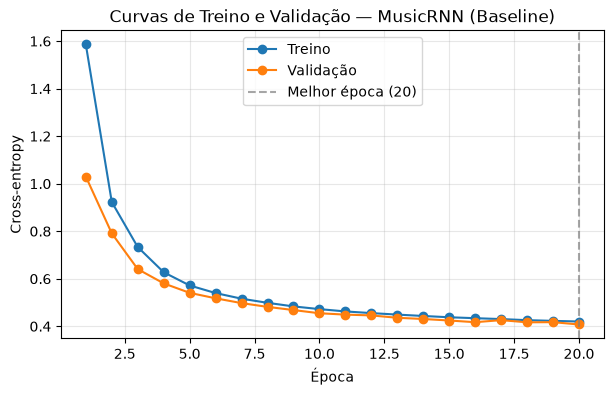

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(rnn_history["train"]) + 1), rnn_history["train"], marker="o", label="Treino")
plt.plot(range(1, len(rnn_history["validation"]) + 1), rnn_history["validation"], marker="o", label="Validação")
plt.axvline(best_rnn_epoch, color="gray", linestyle="--", alpha=0.7, label=f"Melhor época ({best_rnn_epoch})")
plt.title("Curvas de Treino e Validação — MusicRNN (Baseline)")
plt.xlabel("Época")
plt.ylabel("Cross-entropy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [30]:
CHECKPOINT_PATH = BASE_DIR / "rnn_nottingham.pt"

torch.save({
    "epoch": best_rnn_epoch,
    "val_loss": best_rnn_val,
    "model_state_dict": model.state_dict(),
    "vocab_size": VOCAB_SIZE,
    "pad_id": PAD_ID,
    "bos_id": BOS_ID,
    "eos_id": EOS_ID,
    "embedding_dim": model.embedding.embedding_dim,
    "hidden_dim": model.rnn.hidden_size,
    "num_layers": model.rnn.num_layers,
    "history": rnn_history,
}, CHECKPOINT_PATH)

with (BASE_DIR / "rnn_training_history.json").open("w", encoding="utf-8") as f:
    json.dump(rnn_history, f, indent=2)

print("Modelo RNN salvo em:", CHECKPOINT_PATH)

Modelo RNN salvo em: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\rnn_nottingham.pt


## Geração das Músicas (`MusicRNN`)

In [31]:
import torch
import torch.nn as nn
from pathlib import Path

if "BASE_DIR" not in globals():
    _project_root = (
        Path.cwd() / "UFMG" / "GenAIMusic"
        if (Path.cwd() / "UFMG" / "GenAIMusic").exists()
        else Path.cwd()
    )
    BASE_DIR = (_project_root / "nottingham_project").resolve()
CHECKPOINT_PATH = BASE_DIR / "rnn_nottingham.pt"
GENERATED_DIR = BASE_DIR / "generated_rnn"
GENERATED_DIR.mkdir(parents=True, exist_ok=True)

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)

VOCAB_SIZE = checkpoint["vocab_size"]
PAD_ID = checkpoint["pad_id"]
BOS_ID = checkpoint["bos_id"]
EOS_ID = checkpoint["eos_id"]
EMBEDDING_DIM = checkpoint.get("embedding_dim", 64)
HIDDEN_DIM = checkpoint.get("hidden_dim", 128)
NUM_LAYERS = checkpoint.get("num_layers", 1)

model = MusicRNN(
    VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Modelo RNN carregado.")
print("Vocabulário:", VOCAB_SIZE)
print(f"Camadas RNN: {NUM_LAYERS} | Embedding dim: {EMBEDDING_DIM} | Hidden dim: {HIDDEN_DIM}")
print("Dispositivo:", device)

Modelo RNN carregado.
Vocabulário: 429
Camadas RNN: 1 | Embedding dim: 64 | Hidden dim: 128
Dispositivo: cuda


In [32]:
import torch.nn.functional as F

def generate_sequence(
    model,
    max_tokens=1500,
    temperature=0.9,
    top_k=20,
    top_p=0.9,
    seed=None,
):
    if temperature <= 0:
        raise ValueError("temperature deve ser maior que zero")

    if seed is not None:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

    sequence = [BOS_ID]
    current = torch.tensor([[BOS_ID]], dtype=torch.long, device=device)
    hidden = None

    with torch.inference_mode():
        for _ in range(max_tokens):
            logits, hidden = model(current, hidden)
            logits = logits[0, -1].float() / temperature

            logits[PAD_ID] = float("-inf")
            logits[BOS_ID] = float("-inf")

            if top_k is not None and 0 < top_k < VOCAB_SIZE:
                threshold = torch.topk(logits, top_k).values[-1]
                logits[logits < threshold] = float("-inf")

            if top_p is not None and 0.0 < top_p < 1.0:
                sorted_logits, sorted_indices = torch.sort(logits, descending=True)
                sorted_probs = F.softmax(sorted_logits, dim=-1)
                cumulative_probs = torch.cumsum(sorted_probs, dim=-1)

                # Remove tokens após atingir top_p, mantendo sempre ao menos o 1º candidato.
                sorted_indices_to_remove = cumulative_probs > top_p
                sorted_indices_to_remove[1:] = sorted_indices_to_remove[:-1].clone()
                sorted_indices_to_remove[0] = False
                logits[sorted_indices[sorted_indices_to_remove]] = float("-inf")

            probs = F.softmax(logits, dim=-1)

            if not torch.isfinite(probs).all() or probs.sum() <= 0:
                break

            next_token = torch.multinomial(probs, num_samples=1).item()
            sequence.append(next_token)

            if next_token == EOS_ID:
                break

            current = torch.tensor([[next_token]], dtype=torch.long, device=device)

    return sequence

In [33]:
from tqdm.auto import tqdm

N_SAMPLES = 5
MAX_TOKENS = 2500

generated_sequences = []

for i in tqdm(range(N_SAMPLES), desc="Gerando músicas"):
    seq = generate_sequence(
        model,
        max_tokens=MAX_TOKENS,
        temperature=0.9,
        top_k=20,
        top_p=0.9,
        seed=42 + i,
    )
    generated_sequences.append(seq)

    print(f"Música {i + 1}: {len(seq)} tokens")

Gerando músicas:   0%|          | 0/5 [00:00<?, ?it/s]

Música 1: 2501 tokens
Música 2: 2501 tokens
Música 3: 2501 tokens
Música 4: 2501 tokens
Música 5: 2501 tokens


In [34]:
midi_paths = []
errors = []

for i, seq in enumerate(tqdm(generated_sequences, desc="Convertendo para MIDI")):
    try:
        midi = tokenizer.decode(seq)
        path = GENERATED_DIR / f"rnn_generated_{i + 1:02d}.mid"
        midi.dump_midi(str(path))
        midi_paths.append(path)
    except Exception as exc:
        errors.append((i + 1, str(exc)))

print("Arquivos MIDI gerados:", len(midi_paths))
for path in midi_paths:
    print(path)

if errors:
    print("\nFalhas de conversão:")
    for idx, error in errors:
        print(f"Música {idx}: {error}")

Convertendo para MIDI:   0%|          | 0/5 [00:00<?, ?it/s]

Arquivos MIDI gerados: 5
C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\generated_rnn\rnn_generated_01.mid
C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\generated_rnn\rnn_generated_02.mid
C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\generated_rnn\rnn_generated_03.mid
C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\generated_rnn\rnn_generated_04.mid
C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\generated_rnn\rnn_generated_05.mid


In [35]:
import pretty_midi
import pandas as pd

rows = []

for path in midi_paths:
    try:
        midi = pretty_midi.PrettyMIDI(str(path))
        notes = [note for inst in midi.instruments for note in inst.notes]

        rows.append({
            "arquivo": path.name,
            "duração_s": round(midi.get_end_time(), 2),
            "instrumentos": len(midi.instruments),
            "notas": len(notes),
            "pitch_min": min((n.pitch for n in notes), default=None),
            "pitch_max": max((n.pitch for n in notes), default=None),
            "válido": len(notes) > 0,
        })
    except Exception as exc:
        rows.append({
            "arquivo": path.name,
            "duração_s": None,
            "instrumentos": None,
            "notas": None,
            "pitch_min": None,
            "pitch_max": None,
            "válido": False,
            "erro": str(exc),
        })

pd.DataFrame(rows)

,arquivo,duração_s,instrumentos,notas,pitch_min,pitch_max,válido
0,rnn_generated_01.mid,78.38,1,416,36,81,True
1,rnn_generated_02.mid,83.00,1,419,36,83,True
2,rnn_generated_03.mid,86.38,1,417,37,83,True
3,rnn_generated_04.mid,85.00,1,409,36,83,True
4,rnn_generated_05.mid,80.50,1,419,36,83,True


In [36]:
import shutil

zip_path = shutil.make_archive(
    str(BASE_DIR / "rnn_generated_midis"),
    "zip",
    root_dir=GENERATED_DIR,
)

print("ZIP criado:", zip_path)

ZIP criado: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\rnn_generated_midis.zip


In [37]:
from pathlib import Path

print("Execução local — MIDIs gerados pela RNN compactados em:", Path(zip_path).resolve())

Execução local — MIDIs gerados pela RNN compactados em: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\rnn_generated_midis.zip


# Treinando o Modelo Principal (`MusicTransformer`)

Implementação nativa em PyTorch de um Transformer causal *decoder-only* (Pre-LN) de 6 camadas (`d_model=256`, `nhead=8`, `dim_feedforward=1024`), equipado com:
- Ativação `GELU` e `Dropout` na soma de embeddings de token e posição (`max_seq_length = WINDOW_SIZE`);
- *Weight tying* entre `embedding` e a projeção linear de saída;
- Inicialização estilo GPT-2 ($\mathcal{N}(0, 0.02)$ e escala residual $1/\sqrt{2L}$), evitando saturação inicial de logits;
- Otimização com `AdamW` separando parâmetros com e sem *weight decay*, `OneCycleLR` (*warmup* + decaimento cosseno) e *Early Stopping*.

In [38]:
import gc
import torch
import torch.nn as nn
from tqdm.auto import tqdm

# assert "train_dataset" in globals() and isinstance(train_dataset, WindowedMusicDataset), (
#     "Execute antes a célula de preparação do WindowedMusicDataset (janelamento compartilhado)."
# )

print("Reutilizando o mesmo dataset janelado da RNN (comparação justa):")
print(f" - Janelas de treino: {len(train_dataset):,}")
print(f" - Janelas de validação: {len(val_dataset):,}")
print(f" - Window size: {WINDOW_SIZE} | Stride: {STRIDE} | Batch size: {BATCH_SIZE}")

Reutilizando o mesmo dataset janelado da RNN (comparação justa):
 - Janelas de treino: 10,734
 - Janelas de validação: 344
 - Window size: 1024 | Stride: 512 | Batch size: 32


In [39]:
class MusicTransformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        d_model=256,
        nhead=8,
        num_layers=6,
        dim_feedforward=1024,
        dropout=0.1,
        max_seq_length=WINDOW_SIZE,
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=PAD_ID,
        )
        self.position_embedding = nn.Embedding(
            max_seq_length,
            d_model,
        )
        self.emb_dropout = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
            activation="gelu",
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            enable_nested_tensor=False,
        )

        self.final_norm = nn.LayerNorm(d_model)
        self.output = nn.Linear(d_model, vocab_size, bias=False)

        self.d_model = d_model
        self.nhead = nhead
        self.num_layers = num_layers
        self.dim_feedforward = dim_feedforward
        self.dropout = dropout
        self.max_seq_length = max_seq_length

        self._init_weights()
        # Weight tying após _init_weights preserva a escala N(0, 0.02) nos logits iniciais
        self.output.weight = self.embedding.weight

    def _init_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, mean=0.0, std=0.02)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Embedding):
                nn.init.normal_(module.weight, mean=0.0, std=0.02)
                if module.padding_idx is not None:
                    module.weight.data[module.padding_idx].zero_()
            elif isinstance(module, nn.LayerNorm):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)

        # Escala GPT-2 nas projeções residuais para estabilizar camadas profundas
        residual_std = 0.02 / ((2 * self.num_layers) ** 0.5)
        for layer in self.transformer.layers:
            nn.init.normal_(layer.self_attn.out_proj.weight, mean=0.0, std=residual_std)
            nn.init.normal_(layer.linear2.weight, mean=0.0, std=residual_std)

    def forward(self, x):
        batch_size, seq_length = x.shape

        if seq_length > self.max_seq_length:
            raise ValueError(
                f"Sequência {seq_length} maior que o limite {self.max_seq_length}."
            )

        positions = torch.arange(seq_length, device=x.device).unsqueeze(0)
        embedded = self.emb_dropout(
            self.embedding(x) + self.position_embedding(positions)
        )

        # Máscara causal triangular superior (como PAD está sempre à direita e é ignorado na loss,
        # nenhum token válido atende posições futuras de PAD).
        causal_mask = torch.triu(
            torch.ones(seq_length, seq_length, device=x.device, dtype=torch.bool),
            diagonal=1,
        )

        output = self.transformer(
            embedded,
            mask=causal_mask,
        )
        output = self.final_norm(output)
        return self.output(output)

In [40]:
MAX_SEQ_LENGTH = WINDOW_SIZE

MAX_EPOCHS = 45
MIN_EPOCHS = 15
PATIENCE = 6

model = MusicTransformer(
    vocab_size=VOCAB_SIZE,
    d_model=256,
    nhead=8,
    num_layers=6,
    dim_feedforward=1024,
    dropout=0.1,
    max_seq_length=MAX_SEQ_LENGTH,
).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

# Aplica weight_decay apenas em matrizes 2D das camadas de atenção/FFN (exclui embeddings, biases e LayerNorm)
no_decay_ids = {id(model.embedding.weight), id(model.position_embedding.weight)}
decay_params = [
    p for p in model.parameters()
    if p.requires_grad and p.dim() >= 2 and id(p) not in no_decay_ids
]
no_decay_params = [
    p for p in model.parameters()
    if p.requires_grad and (p.dim() < 2 or id(p) in no_decay_ids)
]

optimizer = torch.optim.AdamW(
    [
        {"params": decay_params, "weight_decay": 1e-2},
        {"params": no_decay_params, "weight_decay": 0.0},
    ],
    lr=2e-4,
    betas=(0.9, 0.98),
    eps=1e-8,
)

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=6e-4,
    epochs=MAX_EPOCHS,
    steps_per_epoch=len(train_loader),
    pct_start=0.08,
    anneal_strategy="cos",
    div_factor=6e-4 / 2e-4,
)

scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

print(f"Parâmetros totais do MusicTransformer: {sum(p.numel() for p in model.parameters()):,}")
print(f" - Com weight decay: {sum(p.numel() for p in decay_params):,}")
print(f" - Sem weight decay: {sum(p.numel() for p in no_decay_params):,}")
print(f"Dispositivo: {device} | Batch size: {train_loader.batch_size} | Steps/época: {len(train_loader)}")

Parâmetros totais do MusicTransformer: 5,111,040
 - Com weight decay: 4,718,592
 - Sem weight decay: 392,448
Dispositivo: cuda | Batch size: 32 | Steps/época: 336


In [41]:
def run_epoch(loader, training, epoch, phase):
    model.train(training)

    total_loss = 0.0
    total_tokens = 0

    progress = tqdm(
        loader,
        desc=f"Época {epoch} — {phase}",
        leave=False
    )

    for inputs, targets in progress:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                logits = model(inputs)

                loss = criterion(
                    logits.reshape(-1, VOCAB_SIZE),
                    targets.reshape(-1)
                )

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)

                nn.utils.clip_grad_norm_(
                    model.parameters(),
                    1.0
                )

                scale_before = scaler.get_scale()

                scaler.step(optimizer)
                scaler.update()

                if scaler.get_scale() >= scale_before:
                    scheduler.step()

        valid_tokens = (targets != PAD_ID).sum().item()

        total_loss += loss.detach().item() * valid_tokens
        total_tokens += valid_tokens

        progress.set_postfix(
            loss=f"{total_loss / max(total_tokens, 1):.4f}"
        )

        del inputs, targets, logits, loss

    return total_loss / max(total_tokens, 1)

In [42]:
tf_history = {
    "train": [],
    "validation": [],
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
TF_CHECKPOINT_PATH = BASE_DIR / "transformer_nottingham.pt"

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = run_epoch(train_loader, True, epoch, "Treino")
    val_loss = run_epoch(val_loader, False, epoch, "Validação")

    tf_history["train"].append(train_loss)
    tf_history["validation"].append(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Época {epoch:02d}/{MAX_EPOCHS} | "
        f"Treino: {train_loss:.4f} | "
        f"Validação: {val_loss:.4f} | "
        f"LR: {current_lr:.7f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "val_loss": val_loss,
                "vocab_size": VOCAB_SIZE,
                "d_model": model.d_model,
                "nhead": model.nhead,
                "num_layers": model.num_layers,
                "dim_feedforward": model.dim_feedforward,
                "dropout": model.dropout,
                "max_seq_length": model.max_seq_length,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "history": tf_history,
            },
            TF_CHECKPOINT_PATH,
        )
        print("  -> Melhor modelo salvo.")
    else:
        epochs_without_improvement += 1

    if epoch >= MIN_EPOCHS and epochs_without_improvement >= PATIENCE:
        print(
            f"Early Stopping acionado na época {epoch}: "
            f"{PATIENCE} épocas sem melhoria na validação."
        )
        break

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

with (BASE_DIR / "transformer_training_history.json").open("w", encoding="utf-8") as f:
    json.dump(tf_history, f, indent=2)

print(f"\nMelhor época Transformer: {best_epoch}")
print(f"Melhor Val Loss Transformer: {best_val_loss:.4f}")

Época 1 — Treino:   0%|          | 0/336 [00:00<?, ?it/s]

Época 1 — Validação:   0%|          | 0/11 [00:00<?, ?it/s]

Época 01/45 | Treino: 1.8899 | Validação: 1.4413 | LR: 0.0002716
  -> Melhor modelo salvo.


Época 2 — Treino:   0%|          | 0/336 [00:00<?, ?it/s]

Época 2 — Validação:   0%|          | 0/11 [00:00<?, ?it/s]

Época 02/45 | Treino: 1.1308 | Validação: 0.5837 | LR: 0.0004350
  -> Melhor modelo salvo.


... (50 outputs left out)

Época 19/45 | Treino: 0.1203 | Validação: 0.1770 | LR: 0.0004174


Época 20 — Treino:   0%|          | 0/336 [00:00<?, ?it/s]

Época 20 — Validação:   0%|          | 0/11 [00:00<?, ?it/s]

Época 20/45 | Treino: 0.1155 | Validação: 0.1800 | LR: 0.0003961
Early Stopping acionado na época 20: 6 épocas sem melhoria na validação.

Melhor época Transformer: 14
Melhor Val Loss Transformer: 0.1690


In [43]:
checkpoint = torch.load(
    BASE_DIR / "transformer_nottingham.pt",
    map_location=device,
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Checkpoint carregado: época {checkpoint['epoch']}")
print(f"Melhor Val Loss: {checkpoint['val_loss']:.4f}")

Checkpoint carregado: época 14
Melhor Val Loss: 0.1690


## Curvas de Treino e Validação (`MusicRNN` vs. `MusicTransformer`)

Gera a figura comparativa das curvas de *Cross-Entropy* de treino e validação dos dois modelos para inclusão direta no artigo ISMIR (Seção 2.8e do enunciado).

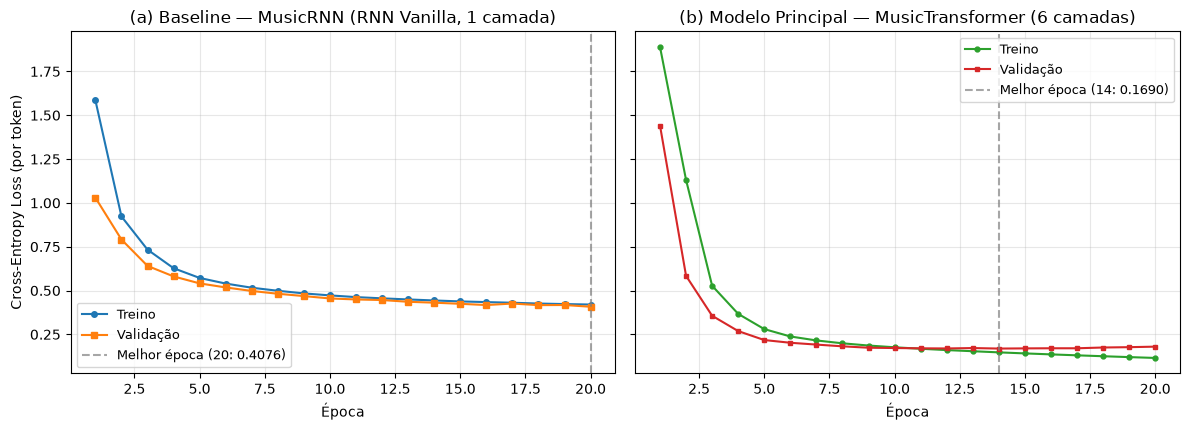

Figura salva em: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\training_curves.png
MusicRNN         -> Melhor Val CE: 0.4076 | Val PPL: 1.503 (época 20)
MusicTransformer -> Melhor Val CE: 0.1690 | Val PPL: 1.184 (época 14)


In [44]:
from pathlib import Path
import json
import math
import numpy as np
import matplotlib.pyplot as plt

if "BASE_DIR" not in globals():
    _project_root = (
        Path.cwd() / "UFMG" / "GenAIMusic"
        if (Path.cwd() / "UFMG" / "GenAIMusic").exists()
        else Path.cwd()
    )
    BASE_DIR = (_project_root / "nottingham_project").resolve()
rnn_hist_path = BASE_DIR / "rnn_training_history.json"
tf_hist_path = BASE_DIR / "transformer_training_history.json"

r_hist = (
    json.loads(rnn_hist_path.read_text(encoding="utf-8"))
    if rnn_hist_path.exists()
    else rnn_history
)
t_hist = (
    json.loads(tf_hist_path.read_text(encoding="utf-8"))
    if tf_hist_path.exists()
    else tf_history
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)

# Painel (a): Baseline MusicRNN
r_epochs = range(1, len(r_hist["train"]) + 1)
r_best_ep = int(np.argmin(r_hist["validation"])) + 1
r_best_val = min(r_hist["validation"])
axes[0].plot(r_epochs, r_hist["train"], marker="o", markersize=4, label="Treino", color="#1f77b4")
axes[0].plot(r_epochs, r_hist["validation"], marker="s", markersize=4, label="Validação", color="#ff7f0e")
axes[0].axvline(r_best_ep, color="gray", linestyle="--", alpha=0.7, label=f"Melhor época ({r_best_ep}: {r_best_val:.4f})")
axes[0].set_title("(a) Baseline — MusicRNN (RNN Vanilla, 1 camada)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Cross-Entropy Loss (por token)")
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=9)

# Painel (b): Modelo Principal MusicTransformer
t_epochs = range(1, len(t_hist["train"]) + 1)
t_best_ep = int(np.argmin(t_hist["validation"])) + 1
t_best_val = min(t_hist["validation"])
axes[1].plot(t_epochs, t_hist["train"], marker="o", markersize=3.5, label="Treino", color="#2ca02c")
axes[1].plot(t_epochs, t_hist["validation"], marker="s", markersize=3.5, label="Validação", color="#d62728")
axes[1].axvline(t_best_ep, color="gray", linestyle="--", alpha=0.7, label=f"Melhor época ({t_best_ep}: {t_best_val:.4f})")
axes[1].set_title("(b) Modelo Principal — MusicTransformer (6 camadas)")
axes[1].set_xlabel("Época")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=9)

plt.tight_layout()
curves_fig_path = BASE_DIR / "training_curves.png"
plt.savefig(curves_fig_path, dpi=200)
plt.show()

print(f"Figura salva em: {curves_fig_path}")
print(f"MusicRNN         -> Melhor Val CE: {r_best_val:.4f} | Val PPL: {math.exp(r_best_val):.3f} (época {r_best_ep})")
print(f"MusicTransformer -> Melhor Val CE: {t_best_val:.4f} | Val PPL: {math.exp(t_best_val):.3f} (época {t_best_ep})")

## Gerando as músicas

In [45]:
import os
import zipfile
from pathlib import Path
import torch
import torch.nn.functional as F

if "BASE_DIR" not in globals():
    _project_root = (
        Path.cwd() / "UFMG" / "GenAIMusic"
        if (Path.cwd() / "UFMG" / "GenAIMusic").exists()
        else Path.cwd()
    )
    BASE_DIR = (_project_root / "nottingham_project").resolve()

CHECKPOINT_PATH = BASE_DIR / "transformer_nottingham.pt"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

if "model" not in globals() or not isinstance(model, MusicTransformer):
    model = MusicTransformer(
        vocab_size=checkpoint.get("vocab_size", VOCAB_SIZE),
        d_model=checkpoint.get("d_model", 256),
        nhead=checkpoint.get("nhead", 8),
        num_layers=checkpoint.get("num_layers", 6),
        dim_feedforward=checkpoint.get("dim_feedforward", 1024),
        dropout=checkpoint.get("dropout", 0.1),
        max_seq_length=checkpoint.get("max_seq_length", WINDOW_SIZE),
    ).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Modelo carregado — época {checkpoint['epoch']}")
print(f"Validation Loss: {checkpoint['val_loss']:.4f}")

Modelo carregado — época 14
Validation Loss: 0.1690


In [46]:
def generate_music(
    model,
    temperature=0.9,
    top_k=20,
    top_p=0.9,
    max_tokens=1500,
    seed=None,
):
    if temperature <= 0:
        raise ValueError("temperature deve ser maior que zero")

    if seed is not None:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

    sequence = [BOS_ID]
    max_context = WINDOW_SIZE if "WINDOW_SIZE" in globals() else 1024
    model.eval()

    with torch.inference_mode():
        for _ in range(max_tokens):
            # Mantém a janela de contexto dentro do tamanho visto no treino (0..1023 posições).
            context = sequence[-max_context:]
            inputs = torch.tensor(
                [context],
                dtype=torch.long,
                device=device
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                logits = model(inputs)

            logits = logits[0, -1, :].float() / temperature

            logits[PAD_ID] = float("-inf")
            logits[BOS_ID] = float("-inf")

            if top_k is not None and 0 < top_k < VOCAB_SIZE:
                threshold = torch.topk(logits, top_k).values[-1]
                logits[logits < threshold] = float("-inf")

            if top_p is not None and 0.0 < top_p < 1.0:
                sorted_logits, sorted_indices = torch.sort(logits, descending=True)
                sorted_probs = F.softmax(sorted_logits, dim=-1)
                cumulative_probs = torch.cumsum(sorted_probs, dim=-1)

                # Remove tokens após atingir top_p, mantendo sempre ao menos o 1º candidato.
                sorted_indices_to_remove = cumulative_probs > top_p
                sorted_indices_to_remove[1:] = sorted_indices_to_remove[:-1].clone()
                sorted_indices_to_remove[0] = False
                logits[sorted_indices[sorted_indices_to_remove]] = float("-inf")

            probabilities = F.softmax(logits, dim=-1)
            if not torch.isfinite(probabilities).all() or probabilities.sum() <= 0:
                break

            next_token = torch.multinomial(
                probabilities,
                num_samples=1
            ).item()

            sequence.append(next_token)

            if next_token == EOS_ID:
                break

    return sequence

In [47]:
OUTPUT_DIR = str(BASE_DIR / "generated_transformer")

os.makedirs(OUTPUT_DIR, exist_ok=True)

generated_sequences = []

for i in range(1, 6):

    print(f"Gerando música {i}/5...")

    sequence = generate_music(
        model,
        temperature=0.9,
        top_k=20,
        top_p=0.9,
        max_tokens=1500,
        seed=42 + (i - 1),
    )

    generated_sequences.append(sequence)

    midi = tokenizer.decode(sequence)

    output_path = os.path.join(
        OUTPUT_DIR,
        f"transformer_generated_{i:02d}.mid"
    )

    midi.dump_midi(output_path)

    print(
        f"Salva: transformer_generated_{i:02d}.mid "
        f"({len(sequence)} tokens)"
    )

print("\nGeração concluída!")

Gerando música 1/5...
Salva: transformer_generated_01.mid (1501 tokens)
Gerando música 2/5...
Salva: transformer_generated_02.mid (1501 tokens)
Gerando música 3/5...
Salva: transformer_generated_03.mid (1056 tokens)
Gerando música 4/5...
Salva: transformer_generated_04.mid (1501 tokens)
Gerando música 5/5...
Salva: transformer_generated_05.mid (1279 tokens)

Geração concluída!


In [48]:
ZIP_PATH = BASE_DIR / "transformer_generated_music.zip"

with zipfile.ZipFile(ZIP_PATH, "w") as zip_file:
    for filename in os.listdir(OUTPUT_DIR):
        filepath = os.path.join(OUTPUT_DIR, filename)
        zip_file.write(filepath, arcname=filename)

print("Execução local — arquivo ZIP salvo em:", ZIP_PATH.resolve())

Execução local — arquivo ZIP salvo em: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\transformer_generated_music.zip


In [49]:
from pathlib import Path
import pandas as pd
import pretty_midi

TEMPERATURES = [0.8, 0.9, 1.0]
N_TEST_PER_TEMP = 5
TEMP_STUDY_DIR = BASE_DIR / "sampling_study"
TEMP_STUDY_DIR.mkdir(parents=True, exist_ok=True)

study_rows = []

for temp in TEMPERATURES:
    temp_dir = TEMP_STUDY_DIR / f"T_{temp:.1f}"
    temp_dir.mkdir(parents=True, exist_ok=True)

    for i in range(N_TEST_PER_TEMP):
        seq = generate_music(
            model,
            temperature=temp,
            top_k=20,
            top_p=0.9,
            max_tokens=1500,
            seed=100 + i,
        )
        ended_with_eos = (seq[-1] == EOS_ID)
        midi = tokenizer.decode(seq)
        midi_path = temp_dir / f"sample_{i + 1:02d}.mid"
        midi.dump_midi(str(midi_path))

        pm = pretty_midi.PrettyMIDI(str(midi_path))
        notes = [n for inst in pm.instruments for n in inst.notes]
        pitches = [n.pitch for n in notes]

        study_rows.append({
            "temperature": temp,
            "amostra": i + 1,
            "tokens": len(seq),
            "encerrou_eos": ended_with_eos,
            "duracao_s": round(pm.get_end_time(), 2),
            "n_notas": len(notes),
            "pitch_range": (max(pitches) - min(pitches)) if pitches else 0,
            "notas_unicas": len(set(pitches)),
        })

study_df = pd.DataFrame(study_rows)
display(
    study_df.groupby("temperature")[["tokens", "encerrou_eos", "duracao_s", "n_notas", "pitch_range", "notas_unicas"]]
    .mean()
    .round(2)
)

,tokens,encerrou_eos,duracao_s,n_notas,pitch_range,notas_unicas
temperature,,,,,,
0.8,1407.8,0.2,50.25,251.6,39.2,15.4
0.9,1501.0,0.0,65.25,268.2,42.4,17.4
1.0,1419.4,0.2,59.35,253.2,39.0,16.8


RNN (baseline) : 107,629 params | épocas 20 | val mínima 0.4076 (época 20)
Transformer    : 5,111,040 params | época do checkpoint 14 | val_loss 0.1690
Músicas de teste: 104 | tokens: 208525


  0%|          | 0/104 [00:00<?, ?it/s]

  0%|          | 0/104 [00:00<?, ?it/s]

,modelo,cross-entropy (teste),perplexidade (teste)
0,RNN (baseline),0.3845,1.469
1,Transformer,0.1281,1.137


RNN:   0%|          | 0/100 [00:00<?, ?it/s]

Transformer: 100 sequências carregadas de transformer_sequences.json
RNN         : 100 amostras | tokens médios 1196 (min 729, max 1201) | terminam com EOS: 1%
Transformer : 100 amostras | tokens médios 1188 (min 774, max 1201) | terminam com EOS: 8%


... (7 outputs left out)

MIDI original  : 37,454 notas | pitch 36–84
Após tokenizar : 37,454 notas | pitch 36–84
Notas retidas  : 100.0%
Teste (real) : 104 peças, 0 com métrica indefinida
RNN          : 100 peças, 0 com métrica indefinida
Transformer  : 100 peças, 0 com métrica indefinida


,Teste (real),RNN,Transformer
métrica,,,
pitch_range,42.692 ± 3.462,45.840 ± 1.488,41.200 ± 5.537
pitch_class_entropy,2.729 ± 0.118,3.281 ± 0.187,2.637 ± 0.180
scale_consistency,0.986 ± 0.021,0.806 ± 0.093,0.991 ± 0.017
polyphony,4.104 ± 0.333,6.376 ± 1.253,4.058 ± 0.557
empty_beat_rate,0.023 ± 0.015,0.026 ± 0.014,0.024 ± 0.014


,|Δ média| RNN,|Δ|/σ_teste RNN,OA RNN,KL RNN,|Δ média| Transformer,|Δ|/σ_teste Transformer,OA Transformer,KL Transformer
métrica,,,,,,,,
pitch_range,3.148,0.91,0.497,4.963,1.492,0.43,0.875,0.224
pitch_class_entropy,0.552,4.67,0.088,12.248,0.093,0.79,0.702,0.741
scale_consistency,0.180,8.64,0.129,13.805,0.006,0.27,0.768,0.879
polyphony,2.272,6.82,0.040,3.314,0.046,0.14,0.905,0.040
empty_beat_rate,0.003,0.20,0.516,2.838,0.002,0.11,0.766,1.660


Métricas em que cada modelo tem maior OA com o teste: {'RNN': 0, 'Transformer': 5}


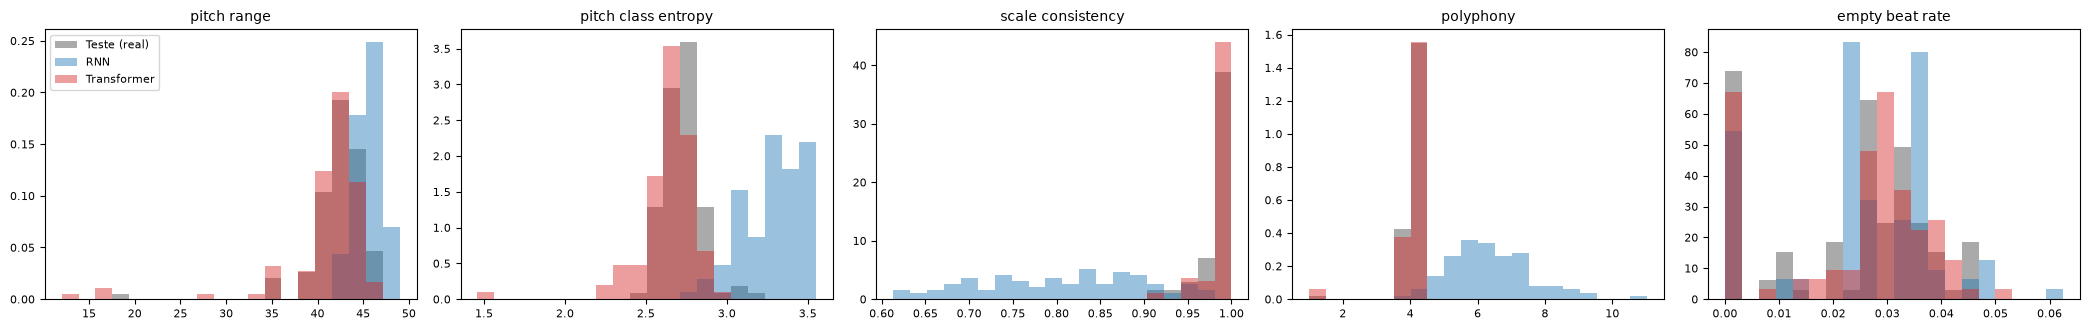

\begin{tabular}{llllrrrr}
\toprule
 & Teste (real) & RNN & Transformer & OA RNN & OA Transformer & KL RNN & KL Transformer \\
\midrule
pitch range & 42.692 ± 3.462 & 45.840 ± 1.488 & 41.200 ± 5.537 & 0.497000 & 0.875000 & 4.963000 & 0.224000 \\
pitch class entropy & 2.729 ± 0.118 & 3.281 ± 0.187 & 2.637 ± 0.180 & 0.088000 & 0.702000 & 12.248000 & 0.741000 \\
scale consistency & 0.986 ± 0.021 & 0.806 ± 0.093 & 0.991 ± 0.017 & 0.129000 & 0.768000 & 13.805000 & 0.879000 \\
polyphony & 4.104 ± 0.333 & 6.376 ± 1.253 & 4.058 ± 0.557 & 0.040000 & 0.905000 & 3.314000 & 0.040000 \\
empty beat rate & 0.023 ± 0.015 & 0.026 ± 0.014 & 0.024 ± 0.014 & 0.516000 & 0.766000 & 2.838000 & 1.660000 \\
\bottomrule
\end{tabular}

Síntese de áudio concluída usando: pretty_midi.synthesize (síntese nativa Python)
ZIP: C:\Users\lucas\Dev\UFMG\GenAIMusic\nottingham_project\entregaveis.zip
['metric_distributions.png', 'metrics_comparison.csv', 'perplexity_test.csv', 'rnn_000.mid', 'rnn_000.wav', 'rnn_001.mid', 'r

In [50]:
# ===== AVALIAÇÃO OBJETIVA FINAL (Seção 2.6 do Enunciado) — 1/7: configuração e checkpoints =====
import json, math, subprocess, shutil, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt, pretty_midi
from tqdm.auto import tqdm
warnings.filterwarnings("ignore", category=RuntimeWarning, module="pretty_midi")

if "BASE_DIR" not in globals():
    _project_root = (
        Path.cwd() / "UFMG" / "GenAIMusic"
        if (Path.cwd() / "UFMG" / "GenAIMusic").exists()
        else Path.cwd()
    )
    BASE_DIR = (_project_root / "nottingham_project").resolve()

N_SAMPLES             = 100
MAX_GEN_TOKENS        = 1200      # ~mediana das músicas de teste; o Transformer corta o contexto em WINDOW_SIZE
SAMPLING              = dict(temperature=0.95, top_k=40, top_p=0.95)  # igual para RNN e Transformer
BASE_SEED             = 1234
OVERWRITE_RNN_SAMPLES = True      # gera as 100 amostras do novo baseline RNN
OVERWRITE_TF_SAMPLES  = False     # reaproveita transformer_sequences.json já gerado se existir
SPECIAL               = {PAD_ID, BOS_ID, EOS_ID}

EVAL_DIR = BASE_DIR / "evaluation"
for sub in ["midi_rnn", "midi_transformer", "midi_test_ref", "audio_rnn", "audio_transformer", "figures"]:
    (EVAL_DIR / sub).mkdir(parents=True, exist_ok=True)

rnn_ckpt = torch.load(BASE_DIR / "rnn_nottingham.pt", map_location=device, weights_only=False)
rnn_model = MusicRNN(
    rnn_ckpt["vocab_size"],
    embedding_dim=rnn_ckpt.get("embedding_dim", 64),
    hidden_dim=rnn_ckpt.get("hidden_dim", 128),
    num_layers=rnn_ckpt.get("num_layers", 1),
).to(device)
rnn_model.load_state_dict(rnn_ckpt["model_state_dict"])
rnn_model.eval()

tf_ckpt = torch.load(BASE_DIR / "transformer_nottingham.pt", map_location=device, weights_only=False)
tf_model = MusicTransformer(
    vocab_size=tf_ckpt.get("vocab_size", VOCAB_SIZE),
    d_model=tf_ckpt.get("d_model", 256),
    nhead=tf_ckpt.get("nhead", 8),
    num_layers=tf_ckpt.get("num_layers", 6),
    dim_feedforward=tf_ckpt.get("dim_feedforward", 1024),
    dropout=tf_ckpt.get("dropout", 0.1),
    max_seq_length=tf_ckpt.get("max_seq_length", WINDOW_SIZE),
).to(device)
tf_model.load_state_dict(tf_ckpt["model_state_dict"])
tf_model.eval()

hv = rnn_ckpt["history"]["validation"]
print(f"RNN (baseline) : {sum(p.numel() for p in rnn_model.parameters()):,} params | épocas {len(hv)} | val mínima {min(hv):.4f} (época {int(np.argmin(hv))+1})")
print(f"Transformer    : {sum(p.numel() for p in tf_model.parameters()):,} params | época do checkpoint {tf_ckpt['epoch']} | val_loss {tf_ckpt['val_loss']:.4f}")


# ===== 2/7: perplexidade no conjunto de teste (mesmo protocolo para os dois modelos) =====
test_sequences = load_sequences("test")
print("Músicas de teste:", len(test_sequences), "| tokens:", sum(len(s) for s in test_sequences))

@torch.no_grad()
def test_perplexity(logits_fn, sequences, window=WINDOW_SIZE, stride=STRIDE):
    total_nll, total_tok = 0.0, 0
    for seq in tqdm(sequences, leave=False):
        L, prev_end, begin = len(seq), 0, 0
        while prev_end < L - 1:
            end = min(begin + window, L - 1)
            x = torch.tensor([seq[begin:end]], dtype=torch.long, device=device)
            y = torch.tensor([seq[begin + 1:end + 1]], dtype=torch.long, device=device)
            logits = logits_fn(x).float()
            n_new = end - prev_end                      # cada token do teste é contado uma única vez
            total_nll += F.cross_entropy(logits[0, -n_new:], y[0, -n_new:], reduction="sum").item()
            total_tok += n_new
            prev_end, begin = end, begin + stride
    return total_nll / total_tok

def rnn_logits(x):
    out = rnn_model(x)
    return out[0] if isinstance(out, tuple) else out

def tf_logits(x):
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
        return tf_model(x)

rows = []
for name, fn in [("RNN (baseline)", rnn_logits), ("Transformer", tf_logits)]:
    ce = test_perplexity(fn, test_sequences)
    rows.append({"modelo": name, "cross-entropy (teste)": round(ce, 4), "perplexidade (teste)": round(math.exp(ce), 3)})
ppl_df = pd.DataFrame(rows)
ppl_df.to_csv(EVAL_DIR / "perplexity_test.csv", index=False)
display(ppl_df)


# ===== 3/7: 100 amostras por modelo (mesma amostragem; sequências salvas em JSON) =====
def gen_rnn(seed): return generate_sequence(rnn_model, max_tokens=MAX_GEN_TOKENS, seed=seed, **SAMPLING)
def gen_tf(seed):  return generate_music(tf_model, max_tokens=MAX_GEN_TOKENS, seed=seed, **SAMPLING)

def generate_many(gen_fn, n, path, desc, overwrite=True):
    if path.exists() and not overwrite:
        data = json.loads(path.read_text(encoding="utf-8"))
        print(f"{desc}: {len(data)} sequências carregadas de {path.name}")
        return data
    seqs = [gen_fn(BASE_SEED + i) for i in tqdm(range(n), desc=desc)]
    path.write_text(json.dumps(seqs), encoding="utf-8")
    return seqs

rnn_seqs = generate_many(gen_rnn, N_SAMPLES, EVAL_DIR / "rnn_sequences.json", "RNN", overwrite=OVERWRITE_RNN_SAMPLES)
tf_seqs  = generate_many(gen_tf,  N_SAMPLES, EVAL_DIR / "transformer_sequences.json", "Transformer", overwrite=OVERWRITE_TF_SAMPLES)
for name, seqs in [("RNN", rnn_seqs), ("Transformer", tf_seqs)]:
    lens = np.array([len(s) for s in seqs])
    print(f"{name:12s}: {len(seqs)} amostras | tokens médios {lens.mean():.0f} (min {lens.min()}, max {lens.max()}) | terminam com EOS: {np.mean([s[-1] == EOS_ID for s in seqs]):.0%}")


# ===== 4/7: tokens -> MIDI -> notas; conjunto real passa pelo mesmo caminho (cortado em MAX_GEN_TOKENS) =====
def ids_to_midi(ids, path):
    tokenizer.decode([int(t) for t in ids if t not in SPECIAL]).dump_midi(str(path))

def load_notes(path):
    pm = pretty_midi.PrettyMIDI(str(path))
    rows = [[n.start, n.end, n.pitch] for inst in pm.instruments if not inst.is_drum for n in inst.notes]
    return np.array(rows, dtype=float).reshape(-1, 3), np.asarray(pm.get_beats(), dtype=float)

def build_set(seqs, out_dir, prefix, desc):
    items, n_fail = [], 0
    for i, ids in enumerate(tqdm(seqs, desc=desc, leave=False)):
        path = out_dir / f"{prefix}_{i:03d}.mid"
        try:
            ids_to_midi(ids, path)
            notes, beats = load_notes(path)
            items.append({"path": path, "notes": notes, "beats": beats})
        except Exception:
            n_fail += 1
    print(f"{desc}: {len(items)} ok, {n_fail} falhas de decodificação")
    return items

sets = {
    "Teste (real)": build_set([s[:MAX_GEN_TOKENS] for s in test_sequences], EVAL_DIR / "midi_test_ref", "test", "Teste"),
    "RNN":          build_set(rnn_seqs, EVAL_DIR / "midi_rnn", "rnn", "RNN"),
    "Transformer":  build_set(tf_seqs,  EVAL_DIR / "midi_transformer", "transformer", "Transformer"),
}

# Checagem de retenção de notas após pitch_range=(36, 89)
test_manifest = pd.read_csv(DATA_DIR / "test.csv")
raw_n, raw_lo, raw_hi = 0, 127, 0
for p in test_manifest["prepared_path"]:
    pitches = [n.pitch for inst in pretty_midi.PrettyMIDI(p).instruments if not inst.is_drum for n in inst.notes]
    raw_n += len(pitches); raw_lo = min(raw_lo, min(pitches)); raw_hi = max(raw_hi, max(pitches))
rt_n, rt_lo, rt_hi, tmp = 0, 127, 0, EVAL_DIR / "_tmp_roundtrip.mid"
for s in tqdm(test_sequences, leave=False):
    ids_to_midi(s, tmp); notes, _ = load_notes(tmp)
    if len(notes): rt_n += len(notes); rt_lo = min(rt_lo, notes[:, 2].min()); rt_hi = max(rt_hi, notes[:, 2].max())
print(f"MIDI original  : {raw_n:,} notas | pitch {raw_lo}–{raw_hi}")
print(f"Após tokenizar : {rt_n:,} notas | pitch {int(rt_lo)}–{int(rt_hi)}")
print(f"Notas retidas  : {rt_n / raw_n:.1%}")


# ===== 5/7: métricas objetivas (numpy) =====
MAJOR_PCS = np.array([0, 2, 4, 5, 7, 9, 11])
def pitch_range(notes): return float(notes[:, 2].max() - notes[:, 2].min())
def pitch_class_entropy(notes):
    h = np.bincount(notes[:, 2].astype(int) % 12, minlength=12).astype(float); p = h / h.sum(); p = p[p > 0]
    return float(-(p * np.log2(p)).sum())
def scale_consistency(notes):
    h = np.bincount(notes[:, 2].astype(int) % 12, minlength=12)
    return float(max(h[(MAJOR_PCS + k) % 12].sum() for k in range(12)) / h.sum())
def _sixteenth_grid(beats, sub=4):
    return np.interp(np.arange(0, (len(beats) - 1) * sub) / sub, np.arange(len(beats)), beats)
def polyphony(notes, beats):
    t = _sixteenth_grid(beats)
    active = ((notes[:, 0][None, :] <= t[:, None]) & (t[:, None] < notes[:, 1][None, :])).sum(axis=1)
    active = active[active > 0]
    return float(active.mean()) if len(active) else float("nan")
def empty_beat_rate(notes, beats):
    lo, hi = beats[:-1], beats[1:]
    return float(1.0 - ((notes[:, 0][:, None] < hi[None, :]) & (notes[:, 1][:, None] > lo[None, :])).any(axis=0).mean())

METRICS = {
    "pitch_range": lambda n, b: pitch_range(n),
    "pitch_class_entropy": lambda n, b: pitch_class_entropy(n),
    "scale_consistency": lambda n, b: scale_consistency(n),
    "polyphony": polyphony,
    "empty_beat_rate": empty_beat_rate,
}

def compute_metrics(item):
    n, b = item["notes"], item["beats"]
    if len(n) < 2 or len(b) < 3: return {k: np.nan for k in METRICS}
    return {k: fn(n, b) for k, fn in METRICS.items()}

metric_dfs = {name: pd.DataFrame([compute_metrics(it) for it in items]) for name, items in sets.items()}
for name, df in metric_dfs.items():
    print(f"{name:13s}: {len(df)} peças, {int(df.isna().any(axis=1).sum())} com métrica indefinida")
    df.to_csv(EVAL_DIR / f"metrics_{name.split()[0].lower()}.csv", index=False)


# ===== 6/7: comparação de distribuições (Yang & Lerch, 2020): média±desvio, |Δ média|, OA, KL =====
def _hist_probs(a, b, bins=20, eps=1e-6):
    lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
    if hi == lo: return None
    edges = np.linspace(lo, hi, bins + 1)
    pa, pb = np.histogram(a, edges)[0].astype(float), np.histogram(b, edges)[0].astype(float)
    return pa / pa.sum(), pb / pb.sum(), (pa + eps) / (pa + eps).sum(), (pb + eps) / (pb + eps).sum()
def overlap_area(real, gen, bins=20):
    r = _hist_probs(real, gen, bins); return 1.0 if r is None else float(np.minimum(r[0], r[1]).sum())
def kl_divergence(real, gen, bins=20):
    r = _hist_probs(real, gen, bins); return 0.0 if r is None else float((r[2] * np.log(r[2] / r[3])).sum())

real_df, rows = metric_dfs["Teste (real)"], []
for metric in METRICS:
    real = real_df[metric].dropna().to_numpy()
    row = {"métrica": metric, "Teste (real)": f"{real.mean():.3f} ± {real.std():.3f}"}
    for name in ["RNN", "Transformer"]:
        gen = metric_dfs[name][metric].dropna().to_numpy()
        row[name] = f"{gen.mean():.3f} ± {gen.std():.3f}"
        row[f"|Δ média| {name}"] = round(abs(gen.mean() - real.mean()), 3)
        row[f"|Δ|/σ_teste {name}"] = round(abs(gen.mean() - real.mean()) / (real.std() + 1e-12), 2)
        row[f"OA {name}"] = round(overlap_area(real, gen), 3)
        row[f"KL {name}"] = round(kl_divergence(real, gen), 3)
    rows.append(row)
results = pd.DataFrame(rows).set_index("métrica")
results.to_csv(EVAL_DIR / "metrics_comparison.csv")
display(results[["Teste (real)", "RNN", "Transformer"]])
display(results[[c for c in results.columns if c.startswith(("|Δ", "OA", "KL"))]])
wins = {"RNN": 0, "Transformer": 0}
for m in METRICS:
    wins["RNN" if results.loc[m, "OA RNN"] > results.loc[m, "OA Transformer"] else "Transformer"] += 1
print("Métricas em que cada modelo tem maior OA com o teste:", wins)

fig, axes = plt.subplots(1, len(METRICS), figsize=(4.2 * len(METRICS), 3.4))
colors = {"Teste (real)": "#444444", "RNN": "#1f77b4", "Transformer": "#d62728"}
for ax, metric in zip(axes, METRICS):
    allv = np.concatenate([metric_dfs[n][metric].dropna().to_numpy() for n in metric_dfs])
    edges = np.linspace(allv.min(), allv.max() if allv.max() > allv.min() else allv.min() + 1, 21)
    for name, df in metric_dfs.items():
        ax.hist(df[metric].dropna(), bins=edges, density=True, alpha=0.45, label=name, color=colors[name])
    ax.set_title(metric.replace("_", " "), fontsize=10); ax.tick_params(labelsize=8)
axes[0].legend(fontsize=8); plt.tight_layout()
plt.savefig(EVAL_DIR / "figures" / "metric_distributions.png", dpi=200); plt.show()
latex_df = results[["Teste (real)", "RNN", "Transformer", "OA RNN", "OA Transformer", "KL RNN", "KL Transformer"]].copy()
latex_df.index = [m.replace("_", " ") for m in latex_df.index]
try:
    print(latex_df.to_latex(escape=False))
except ImportError:
    print(latex_df.to_string())


# ===== 7/7: áudio (.wav) das 5 primeiras de cada modelo + pacote .zip (compatível com Windows/Linux) =====
import os
import wave
from scipy.io import wavfile

def _find_soundfont():
    env_sf = os.environ.get("SOUNDFONT")
    candidates = [
        Path(env_sf) if env_sf else None,
        BASE_DIR / "soundfonts" / "FluidR3_GM.sf2",
        BASE_DIR / "soundfonts" / "TimGM6mb.sf2",
        Path("/usr/share/sounds/sf2/FluidR3_GM.sf2"),
        Path("/usr/share/soundfonts/FluidR3_GM.sf2"),
    ]
    for c in candidates:
        if c is not None and c.is_file():
            return c
    return None

def _harmonic_wave(phase):
    # Timbre harmônico suave para síntese nativa caso FluidSynth não esteja instalado
    return (
        np.sin(phase)
        + 0.45 * np.sin(2.0 * phase)
        + 0.20 * np.sin(3.0 * phase)
        + 0.10 * np.sin(4.0 * phase)
    )

def render_midi_to_wav(midi_path: Path, wav_path: Path, sr: int = 44100) -> str:
    fluidsynth_bin = shutil.which("fluidsynth")
    sf2 = _find_soundfont()
    if fluidsynth_bin and sf2 is not None:
        subprocess.run(
            [fluidsynth_bin, "-ni", "-F", str(wav_path), "-r", str(sr), str(sf2), str(midi_path)],
            check=True,
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL,
        )
        return f"FluidSynth ({sf2.name})"

    pm = pretty_midi.PrettyMIDI(str(midi_path))
    audio = pm.synthesize(fs=sr, wave=_harmonic_wave)
    if audio.size == 0:
        audio = np.zeros(sr, dtype=np.float32)
    peak = float(np.max(np.abs(audio)))
    if peak > 0:
        audio = audio / peak * 0.90
    pcm16 = np.clip(audio * 32767.0, -32768, 32767).astype(np.int16)
    try:
        wavfile.write(str(wav_path), sr, pcm16)
    except Exception:
        with wave.open(str(wav_path), "wb") as wf:
            wf.setnchannels(1)
            wf.setsampwidth(2)
            wf.setframerate(sr)
            wf.writeframes(pcm16.tobytes())
    return "pretty_midi.synthesize (síntese nativa Python)"

DELIV = BASE_DIR / "entregaveis"
if DELIV.exists():
    shutil.rmtree(DELIV)

synth_backend_used = None
for key, tag in [("RNN", "baseline_rnn"), ("Transformer", "modelo_transformer")]:
    (DELIV / tag).mkdir(parents=True)
    for it in sets[key][:5]:
        wav = DELIV / tag / (it["path"].stem + ".wav")
        synth_backend_used = render_midi_to_wav(it["path"], wav, sr=44100)
        shutil.copy2(it["path"], DELIV / tag / it["path"].name)

print("Síntese de áudio concluída usando:", synth_backend_used)
(DELIV / "resultados").mkdir()
for f in ["perplexity_test.csv", "metrics_comparison.csv"]:
    shutil.copy2(EVAL_DIR / f, DELIV / "resultados" / f)
shutil.copy2(EVAL_DIR / "figures" / "metric_distributions.png", DELIV / "resultados" / "metric_distributions.png")
if (BASE_DIR / "training_curves.png").exists():
    shutil.copy2(BASE_DIR / "training_curves.png", EVAL_DIR / "figures" / "training_curves.png")
    shutil.copy2(BASE_DIR / "training_curves.png", DELIV / "resultados" / "training_curves.png")
print("ZIP:", shutil.make_archive(str(BASE_DIR / "entregaveis"), "zip", root_dir=DELIV))
print(sorted(p.name for p in DELIV.rglob("*") if p.is_file()))